# Kesenjangan Jangkauan Sekolah Dasar Negeri di Kota Bandar Lampung

**UAS Analitika Perkotaan (PL25-41003) — Semester Ganjil 2026/2027 — Kelas RA, Kelompok 1**

| No | Anggota | NIM |
|---|---|---|
| 1 | Ifnaini Dwi Fajarrini | 123220085 |
| 2 | Echi Mutiara Jhuanna | 123220122 |
| 3 | Muhammad Firdaus | 123220134 |
| 4 | Syifa Putri | 123220160 |
| 5 | Naila Amira | 123220177 |

**Isi notebook:** 1) Rumusan isu dan pertanyaan analitik · 2) Data, sumber, dan kualitas data · 3) Jangkauan jaringan jalan vs. radius 1 km (P1) · 4) Rasio SD per 1.000 anak vs. kepadatan penduduk (P2) · 5) Pengelompokan kelurahan dan penentuan prioritas (P3) · 6) Rekomendasi, *trade-off*, dan keterbatasan · 7) Daftar pustaka.

**Catatan reproduksibilitas.** Notebook dijalankan dari folder `notebook/` pada environment conda `analitika-perkotaan`. Seluruh berkas dibaca lewat jalur relatif (`../data/raw/...`) dan hasil olahan ditulis ke `../data/clean/...`. Angka pada teks interpretasi dihasilkan langsung dari kode (bukan diketik manual) sehingga selalu konsisten dengan keluaran.

## 1. Rumusan Isu Perencanaan dan Pertanyaan Analitik

### 1.1 Latar belakang dan masalah perencanaan

Sekolah dasar (SD) adalah layanan dasar yang diakses anak usia 7–12 tahun dengan berjalan kaki atau diantar dalam jarak pendek. Di Kota Bandar Lampung (20 kecamatan, 126 kelurahan), sebaran SD Negeri tidak otomatis mengikuti sebaran anak usia sekolah: kelurahan kawasan pusat kota cenderung padat dan memiliki banyak sekolah berdekatan, sedangkan kelurahan di pinggiran kota berbukit berisiko memiliki anak yang harus menempuh jarak jauh melalui jaringan jalan yang berkelok. Karena sistem penerimaan murid baru berorientasi domisili, jarak rumah–sekolah menjadi penentu nyata akses pendidikan dasar.

**Lokasi studi:** seluruh 126 kelurahan di Kota Bandar Lampung, dengan perhatian khusus pada perbandingan kelurahan pusat kota dan kelurahan pinggiran.
**Kelompok terdampak:** penduduk anak usia 7–12 tahun (usia SD) beserta keluarganya.
**Indikasi awal masalah:** SD Negeri tidak tersebar merata antar-kelurahan — sebagian kelurahan tidak memiliki satu pun SD Negeri di dalam batas administrasinya (dihitung pada Bab 2.6), sementara ukuran jangkauan sederhana (radius garis lurus) berpotensi menyembunyikan rute jalan yang jauh.

### 1.2 Pertanyaan analitik

| | Pertanyaan analitik | Variabel | Unit analisis | Metode | Keluaran |
|---|---|---|---|---|---|
| **P1** (spasial & jaringan) | Kelurahan mana yang memiliki jarak tempuh terjauh melalui jaringan jalan menuju SD Negeri terdekat, dan bagaimana perubahan peringkatnya bila jangkauan diukur dengan jumlah SD dalam radius 1 km? | jarak jaringan jalan kaki ke SDN terdekat (m); jumlah SDN dalam radius 1.000 m | kelurahan (126) | graf jalan OSM + rute terpendek; *buffer* metrik + *spatial join*; korelasi peringkat | peta *choropleth*, tabel dan grafik perubahan peringkat |
| **P2** (non-spasial) | Apakah rasio jumlah SD per 1.000 anak usia 7–12 tahun berhubungan dengan kepadatan penduduk di tingkat kelurahan? | rasio SD per 1.000 anak; kepadatan penduduk (jiwa/km²) | kelurahan (126) | SQL/pandas, statistik deskriptif, uji normalitas, korelasi Spearman & Pearson | tabel agregat, *boxplot*, *scatter* kuadran |
| **P3** (sintesis) | Bagaimana pengelompokan kelurahan menurut ketersediaan dan keterjangkauan SD, dan kelurahan mana yang menjadi prioritas penambahan fasilitas? | gabungan 4 indikator P1–P2 | kelurahan (126) | *K-Means* + aturan prioritas berbasis ambang | tipologi kelurahan, daftar prioritas USB/RKB, peta |

### 1.3 Relevansi kebijakan
Hasil analisis ditujukan bagi dinas pendidikan dan perencana kota untuk (a) menetapkan lokasi **unit sekolah baru (USB)** di kelurahan yang jauh dari SD, (b) menetapkan **penambahan ruang kelas baru (RKB)** di kelurahan padat yang SD-nya dekat tetapi terbebani, dan (c) memilih intervensi non-bangunan (angkutan/rute aman sekolah) di kelurahan jauh yang jumlah anaknya kecil.

### 1.4 Persiapan lingkungan dan parameter
Sel berikut memuat pustaka dan menetapkan parameter analisis. CRS kerja untuk semua ukuran jarak/luas adalah **EPSG:32748 (WGS 84 / UTM zona 48S)** karena satuannya meter; EPSG:4326 hanya dipakai untuk penyimpanan koordinat mentah.

In [1]:
import os, sys, warnings, sqlite3
from pathlib import Path
warnings.filterwarnings("ignore")

# Penjaga PROJ: arahkan ke basis data PROJ milik environment ini bila ada
# (mencegah bentrok dengan instalasi PROJ lain di komputer).
_proj = Path(sys.prefix) / "Library" / "share" / "proj"
if _proj.is_dir():
    os.environ["PROJ_LIB"] = str(_proj)
    os.environ["PROJ_DATA"] = str(_proj)

import numpy as np, pandas as pd, geopandas as gpd, networkx as nx, osmnx as ox
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display, Markdown

# --- jalur relatif ---
RAW = Path("../data/raw")
CLEAN = Path("../data/clean")
GAMBAR = CLEAN / "gambar"
GAMBAR.mkdir(parents=True, exist_ok=True)

# --- parameter analisis ---
CRS_GEO, CRS_UTM = 4326, 32748
RADIUS_M = 1000          # radius jangkauan jalan kaki (TOR: contoh 1.000 m)
AMBANG_JARAK_M = 1000    # ambang 'jauh': jarak jaringan > 1.000 m
RANDOM_STATE = 42

sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight"})


def md_out(teks):
    display(Markdown(teks))


def fmt(x, d=0):
    # format angka gaya Indonesia: 1.234,5
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")


def kunci(s):
    # kunci pencocokan nama: huruf kecil tanpa spasi/tanda baca
    return s.astype(str).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)


def outlier_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

print("Python:", sys.version.split()[0], "| geopandas", gpd.__version__, "| osmnx", ox.__version__)

Python: 3.12.14 | geopandas 1.1.4 | osmnx 2.1.1


## 2. Akuisisi Data, Sumber, dan Kualitas Data

### 2.1 Sumber data

| Data | Berkas (`data/raw/`) | Sumber / cara perolehan | Cakupan & unit | Keterangan tahun |
|---|---|---|---|---|
| Batas administrasi kelurahan | `batas_kelurahan_bdl.geojson` | Ina-Geoportal (BIG), diunduh dan dipotong ke Kota Bandar Lampung | 126 poligon kelurahan, 20 kecamatan | tahun tidak tercantum pada berkas |
| Titik SD Negeri | `Daftar_SD_Negeri_Bandar_Lampung.csv` (+`.xlsx`) | SPMB Online (rencana sumber kelompok); atribut: NPSN, peserta didik, rombel, koordinat | 167 SD Negeri, unit: sekolah | tahun tidak tercantum pada berkas |
| Seluruh sekolah (termasuk SD swasta) | `sekolah_bdl.csv`, `sekolah_bdl.geojson` | berkas dataset kursus (struktur kolom sama dengan daftar SD Negeri) | 1.143 satuan pendidikan; dipakai hanya untuk uji sensitivitas SD swasta | tahun tidak tercantum pada berkas |
| Indikator kelurahan (PODES) | `bdl_kelurahan.csv`, `bdl.sqlite` | dataset kursus berbasis PODES BPS | 126 kelurahan; kepadatan penduduk dan jumlah sekolah | tahun pendataan tidak tercantum pada berkas |
| Penduduk per kecamatan | `Data_Kependudukan_Bandar_Lampung.xlsx` | BPS Kota Bandar Lampung | 20 kecamatan; jumlah penduduk (ribu jiwa), laju pertumbuhan 2020–2025, kepadatan | memuat laju 2020–2025 (data terbaru 2025) |
| Penduduk usia 7–12 tahun | `Data Estimasi penduduk usia 7–12 tahun.xlsx` | estimasi dari kelompok umur 5–9 dan 10–14 tahun (BPS) dengan asumsi sebaran merata per umur tunggal | tingkat kota | estimasi kelompok |
| Jaringan jalan kaki | `jalan_bdl_osm_walk.graphml` | OpenStreetMap lewat Overpass API (`osmnx`), diunduh 16 November 2026 dengan `data/skrip/unduh_jalan_osm.py` | seluruh kota + penyangga 1,5 km; 36.922 simpul | OSM, akses 16-11-2026 |

Berkas `osm_jalan_pusat_bdl.geojson` dan `osm_poi_pusat_bdl.geojson` dari dataset kursus hanya meliputi pusat kota (±3 km × 3 km) sehingga **tidak cukup** untuk 126 kelurahan; karena itu jaringan jalan seluruh kota diunduh sendiri dari OpenStreetMap (data terbuka, lisensi ODbL, tidak ada data pribadi).

### 2.2 Membaca data mentah dan inventarisasi

In [2]:
kel = gpd.read_file(RAW / "batas_kelurahan_bdl.geojson")
podes = pd.read_csv(RAW / "bdl_kelurahan.csv")
sd_raw = pd.read_csv(RAW / "Daftar_SD_Negeri_Bandar_Lampung.csv", sep=";")
sekolah = pd.read_csv(RAW / "sekolah_bdl.csv")
bps = pd.read_excel(RAW / "Data_Kependudukan_Bandar_Lampung.xlsx")
est = pd.read_excel(RAW / "Data Estimasi penduduk usia 7–12 tahun.xlsx", sheet_name="Penduduk Usia 7-12")

inventaris = pd.DataFrame({
    "tabel": ["batas kelurahan", "PODES kelurahan", "SD Negeri", "semua sekolah", "penduduk kecamatan (BPS)"],
    "baris": [len(kel), len(podes), len(sd_raw), len(sekolah), len(bps)],
    "kolom": [kel.shape[1], podes.shape[1], sd_raw.shape[1], sekolah.shape[1], bps.shape[1]],
})
display(inventaris)
display(est)

,tabel,baris,kolom
0,batas kelurahan,126,5
1,PODES kelurahan,126,34
2,SD Negeri,167,13
3,semua sekolah,1143,13
4,penduduk kecamatan (BPS),21,5


,Kelompok Umur,Jumlah,Estimasi
0,5 - 9 tahun,94954,56972.4
1,10 - 14 tahun,99847,59908.2
2,Estimasi penduduk usia 7–12 tahun,116880.6,NaN
3,Metode estimasi,Diasumsikan jumlah penduduk tersebar merata pa...,NaN


### 2.3 Pemeriksaan kualitas: batas kelurahan, PODES, dan penduduk kecamatan
Pemeriksaan: jumlah baris, kode/nama unik, geometri valid, CRS, nilai kosong, duplikat, pencilan, dan keseragaman nama wilayah (kunci penggabungan antar tabel).

In [3]:
kel["kode"] = kel["kode_permendagri"].astype(int)
qc_batas = pd.Series({
    "jumlah poligon kelurahan": len(kel),
    "kode kelurahan unik": kel["kode"].nunique(),
    "nama kelurahan duplikat": int(kel["nama_des"].duplicated().sum()),
    "jumlah kecamatan": kel["nama_kec"].nunique(),
    "geometri tidak valid": int((~kel.is_valid).sum()),
    "geometri kosong": int(kel.geometry.is_empty.sum()),
    "CRS berkas": str(kel.crs),
}, name="hasil")
display(qc_batas.to_frame())

# nilai kosong pada PODES: hanya kolom SUTET yang kosong (tidak dipakai)
kosong = podes.isna().sum()
print("Kolom PODES dengan nilai kosong:", kosong[kosong > 0].to_dict(), "-> tidak dipakai dalam analisis")
print("Baris duplikat PODES:", int(podes.duplicated().sum()), "| kode_permendagri unik:", podes["kode_permendagri"].nunique())

# kunci join kelurahan: kode_permendagri (nama kelurahan hanya diperiksa)
assert set(kel["kode"]) == set(podes["kode_permendagri"]), "kode kelurahan batas vs PODES tidak identik"
podes_pakai = podes[["kode_permendagri", "nama_des", "kepadatan_pddk", "jml_sd_negeri", "jml_sd_swasta"]].rename(
    columns={"nama_des": "nama_des_podes", "kepadatan_pddk": "kepadatan_podes",
             "jml_sd_negeri": "sd_negeri_podes", "jml_sd_swasta": "sd_swasta_podes"})
kel = kel.merge(podes_pakai, left_on="kode", right_on="kode_permendagri", how="left",
                validate="1:1", suffixes=("", "_p")).drop(columns="kode_permendagri_p")
beda_nama = kel[kunci(kel["nama_des"]) != kunci(kel["nama_des_podes"])][["kode", "nama_des", "nama_des_podes"]]
print(f"Penggabungan poligon-PODES lewat kode: 126/126 cocok. Selisih ejaan nama kelurahan: {len(beda_nama)} baris")
display(beda_nama)

# luas dari geometri UTM vs kolom 'luas' (hektar) pada berkas
kel = kel.to_crs(CRS_UTM)
kel["luas_km2"] = kel.geometry.area / 1e6
rasio_luas = (kel["luas_km2"] * 100 / kel["luas"])
print(f"Luas geometri (km2) x100 / kolom luas (ha): min={rasio_luas.min():.4f}, maks={rasio_luas.max():.4f} -> kolom 'luas' = hektar, konsisten")

# pencilan kepadatan PODES
po = outlier_iqr(kel["kepadatan_podes"])
print("Pencilan IQR kepadatan PODES:", int(po.sum()), "kelurahan (dipertahankan: nilai nyata kawasan padat, bukan galat)")

# --- penduduk kecamatan BPS ---
bps.columns = ["kecamatan", "pop_ribu", "laju_2020_2025", "persen", "kepadatan_bps"]
bps_kota = bps[bps["kecamatan"].str.contains("Bandar Lampung")].iloc[0]
bps_kec = bps[~bps["kecamatan"].str.contains("Bandar Lampung")].copy()
bps_kec["kunci"] = kunci(bps_kec["kecamatan"])
kel["kunci_kec"] = kunci(kel["nama_kec"])
assert set(kel["kunci_kec"]) == set(bps_kec["kunci"]), "nama kecamatan batas vs BPS belum seragam"
peta_nama = dict(zip(bps_kec["kunci"], bps_kec["kecamatan"]))
kel["kecamatan"] = kel["kunci_kec"].map(peta_nama)
print(f"Nama 20 kecamatan seragam dengan BPS lewat kunci teks. Jumlah penduduk kota (BPS): {fmt(bps_kota['pop_ribu']*1000)} jiwa; "
      f"jumlah 20 kecamatan: {fmt(bps_kec['pop_ribu'].sum()*1000)} jiwa")

,hasil
jumlah poligon kelurahan,126
kode kelurahan unik,126
nama kelurahan duplikat,0
jumlah kecamatan,20
geometri tidak valid,0
geometri kosong,0
CRS berkas,EPSG:4326


Kolom PODES dengan nilai kosong: {'dm_permukiman_sutet': 119, 'jml_bangunan_sutet': 123} -> tidak dipakai dalam analisis
Baris duplikat PODES: 0 | kode_permendagri unik: 126
Penggabungan poligon-PODES lewat kode: 126/126 cocok. Selisih ejaan nama kelurahan: 1 baris


,kode,nama_des,nama_des_podes
117,1871191003,Parwata,Perwata


Luas geometri (km2) x100 / kolom luas (ha): min=0.9992, maks=0.9992 -> kolom 'luas' = hektar, konsisten
Pencilan IQR kepadatan PODES: 6 kelurahan (dipertahankan: nilai nyata kawasan padat, bukan galat)
Nama 20 kecamatan seragam dengan BPS lewat kunci teks. Jumlah penduduk kota (BPS): 1.088.200 jiwa; jumlah 20 kecamatan: 1.088.400 jiwa


### 2.4 Pemeriksaan kualitas: titik SD Negeri
Titik SD Negeri adalah data inti analisis jarak, sehingga diperiksa lebih teliti: kelengkapan koordinat, duplikat, posisi terhadap batas kota, kesesuaian label kelurahan dengan lokasi sebenarnya, dan pencilan jumlah peserta didik.

In [4]:
sd = sd_raw.rename(columns={"Nama Satuan Pendidikan": "nama_sekolah", "Peserta Didik": "peserta_didik",
                            "Rombel": "rombel"}).copy()
print("Baris:", len(sd), "| Status:", sd["Status"].unique().tolist(), "| Bentuk:", sd["Bentuk"].unique().tolist())
print("NPSN duplikat:", int(sd["NPSN"].duplicated().sum()))
print("Nilai kosong per kolom (hanya yang > 0):", {k: int(v) for k, v in sd.isna().sum().items() if v > 0})

tanpa_xy = sd[sd["lat"].isna() | sd["lon"].isna()]
print("\nSD tanpa koordinat (dikeluarkan dari analisis spasial, tidak diisi/dikarang):")
display(tanpa_xy[["NPSN", "nama_sekolah", "peserta_didik", "Kecamatan", "Kelurahan"]])

sd_xy = sd.dropna(subset=["lat", "lon"]).copy()
dup_xy = sd_xy[sd_xy.duplicated(["lat", "lon"], keep=False)].sort_values(["lat", "lon"])
print("SD dengan koordinat identik (NPSN berbeda; dianggap sekolah berbeda dalam satu kompleks, dipertahankan):")
display(dup_xy[["NPSN", "nama_sekolah", "Kelurahan", "lat", "lon"]])

sd_gdf = gpd.GeoDataFrame(sd_xy, geometry=gpd.points_from_xy(sd_xy["lon"], sd_xy["lat"]), crs=CRS_GEO).to_crs(CRS_UTM)
n0 = len(sd_gdf)
sd_gdf = gpd.sjoin(sd_gdf, kel[["kode", "nama_des", "kecamatan", "geometry"]], how="left", predicate="within")
assert len(sd_gdf) == n0, "ada titik SD yang jatuh di lebih dari satu poligon"
sd_gdf = sd_gdf.drop(columns="index_right").rename(columns={"kode": "kode_kel", "nama_des": "kel_spasial",
                                                            "kecamatan": "kec_spasial"})
print("\nTitik SD di luar seluruh poligon kelurahan:", int(sd_gdf["kode_kel"].isna().sum()))

label_beda = int((kunci(sd_gdf["Kelurahan"]) != kunci(sd_gdf["kel_spasial"])).sum())
kec_label = kunci(sd_gdf["Kecamatan"].str.replace("KEC. ", "", regex=False))
kec_beda = int((kec_label != kunci(sd_gdf["kec_spasial"])).sum())
print(f"Label kelurahan pada daftar SD tidak sama dengan poligon tempat titiknya berada: {label_beda} dari {len(sd_gdf)} SD")
print(f"Label kecamatan tidak sama dengan poligon: {kec_beda} dari {len(sd_gdf)} SD")

pd_out = outlier_iqr(sd_gdf["peserta_didik"])
print("Pencilan IQR peserta didik:", int(pd_out.sum()), "sekolah | ringkasan:", sd_gdf["peserta_didik"].describe().round(0).to_dict())

Baris: 167 | Status: ['NEGERI'] | Bentuk: ['SD']
NPSN duplikat: 0
Nilai kosong per kolom (hanya yang > 0): {'Pembina': 1, 'lat': 1, 'lon': 1}

SD tanpa koordinat (dikeluarkan dari analisis spasial, tidak diisi/dikarang):


,NPSN,nama_sekolah,peserta_didik,Kecamatan,Kelurahan
102,70058793,SEKOLAH RAKYAT DASAR TERINTEGRASI 35 BANDAR LA...,42,KEC. TANJUNG KARANG BARAT,SEGALA MIDER


SD dengan koordinat identik (NPSN berbeda; dianggap sekolah berbeda dalam satu kompleks, dipertahankan):


,NPSN,nama_sekolah,Kelurahan,lat,lon
108,10807095,SD NEGERI 3 KALIAWI,KALIAWI,-5.4158,105.2506
109,10807128,SD NEGERI 4 KALIAWI,KALIAWI,-5.4158,105.2506
94,10807487,SD NEGERI 2 SUKAJAWA,SUKA JAWA,-5.4089,105.2498
98,10807136,SD NEGERI 4 SUKAJAWA,SUKA JAWA,-5.4089,105.2498



Titik SD di luar seluruh poligon kelurahan: 0
Label kelurahan pada daftar SD tidak sama dengan poligon tempat titiknya berada: 57 dari 166 SD
Label kecamatan tidak sama dengan poligon: 18 dari 166 SD
Pencilan IQR peserta didik: 0 sekolah | ringkasan: {'count': 166.0, 'mean': 401.0, 'std': 176.0, 'min': 43.0, '25%': 254.0, '50%': 388.0, '75%': 515.0, 'max': 820.0}


**Keputusan pembersihan SD Negeri dan dampaknya.**
1. *Satu SD tanpa koordinat* (sekolah baru dengan peserta didik sangat sedikit) **dikeluarkan** dari analisis spasial; koordinat tidak diisi atau diperkirakan karena akan menjadi data rekayasa. Dampak: 166 titik SD Negeri dipakai, dan kelurahan di sekitar lokasi sekolah itu dapat sedikit terlalu pesimistis.
2. *Dua pasangan SD dengan koordinat identik* **dipertahankan** karena NPSN berbeda; keduanya dihitung pada ukuran jumlah SD, tetapi tidak mengubah jarak terdekat.
3. *Label kelurahan pada daftar SD sering berbeda dengan poligon* tempat titik berada (ejaan/penamaan berbeda dan pemekaran). Karena itu SD **diatribusikan ke kelurahan berdasarkan posisi titik (spatial join), bukan berdasarkan nama**; seluruh titik berada di dalam batas kota.
4. *Pencilan peserta didik* tidak dikoreksi karena merupakan variasi ukuran sekolah, bukan galat.

### 2.5 Estimasi penduduk kelurahan dan anak usia 7–12 tahun
Tidak ada data anak usia 7–12 tahun per kelurahan. Estimasi disusun dua tahap dan **asumsinya dinyatakan eksplisit**:

1. **Penduduk kelurahan**: penduduk kecamatan (BPS) dialokasikan ke kelurahan sebanding dengan *kepadatan PODES × luas poligon* (kalibrasi per kecamatan). Dengan demikian total tiap kecamatan sama dengan BPS, sedangkan pembagian di dalam kecamatan mengikuti kepadatan relatif PODES.
2. **Anak usia 7–12 tahun**: proporsi kota (estimasi 7–12 tahun ÷ penduduk kota BPS) diterapkan seragam ke semua kelurahan (struktur umur dianggap sama).

In [5]:
# --- proporsi anak 7-12 tahun tingkat kota ---
anak_kota = 0.6 * float(est.loc[est.iloc[:, 0] == "5 - 9 tahun", "Jumlah"].iloc[0]) + \
            0.6 * float(est.loc[est.iloc[:, 0] == "10 - 14 tahun", "Jumlah"].iloc[0])
anak_kota_berkas = float(est.loc[est.iloc[:, 0].str.contains("Estimasi penduduk", na=False), "Jumlah"].iloc[0])
assert abs(anak_kota - anak_kota_berkas) < 1, "estimasi 7-12 tahun tidak cocok dengan berkas"
pop_kota = float(bps_kota["pop_ribu"]) * 1000
RASIO_ANAK = anak_kota / pop_kota
print(f"Anak 7-12 tahun kota = {fmt(anak_kota)} jiwa; penduduk kota = {fmt(pop_kota)}; proporsi = {RASIO_ANAK:.4f}")

# --- kalibrasi penduduk kelurahan ---
kel["bobot"] = kel["kepadatan_podes"] * kel["luas_km2"]
pop_kec_bps = kel["kunci_kec"].map(bps_kec.set_index("kunci")["pop_ribu"] * 1000)
kel["faktor_kalibrasi"] = pop_kec_bps / kel.groupby("kunci_kec")["bobot"].transform("sum")
kel["penduduk"] = kel["bobot"] * kel["faktor_kalibrasi"]
kel["anak_7_12"] = kel["penduduk"] * RASIO_ANAK
kel["kepadatan"] = kel["penduduk"] / kel["luas_km2"]

kal = kel.groupby("kecamatan").agg(penduduk_bps=("penduduk", "sum"),
                                   penduduk_podes_mentah=("bobot", "sum"),
                                   faktor=("faktor_kalibrasi", "first")).round(2).sort_values("faktor")
display(kal)
md_out(f"**Temuan kualitas data:** penduduk implisit PODES (kepadatan × luas) berbeda dari angka BPS kecamatan, dengan faktor kalibrasi "
       f"**{kal['faktor'].min():.2f}–{kal['faktor'].max():.2f}** (faktor < 1 berarti PODES-derivasi lebih besar dari BPS). "
       f"Jumlah penduduk kota hasil kalibrasi = {fmt(kel['penduduk'].sum())} jiwa (sama dengan jumlah 20 kecamatan BPS) dan "
       f"anak 7–12 tahun = {fmt(kel['anak_7_12'].sum())} jiwa. Perbedaan sumber ini menjadi salah satu keterbatasan (Bab 6).")

Anak 7-12 tahun kota = 116.881 jiwa; penduduk kota = 1.088.200; proporsi = 0.1074


,penduduk_bps,penduduk_podes_mentah,faktor
kecamatan,,,
Teluk Betung Barat,39000.0,62890.37,0.62
Teluk Betung Selatan,38100.0,50212.01,0.76
Way Halim,66900.0,76649.93,0.87
Tanjung Karang Timur,37200.0,42581.76,0.87
Tanjung Senang,63100.0,70776.46,0.89
Tanjung Karang Barat,62200.0,68545.92,0.91
Teluk Betung Utara,49100.0,51192.58,0.96
Teluk Betung Timur,49300.0,51100.22,0.96
Rajabasa,56700.0,57484.89,0.99


**Temuan kualitas data:** penduduk implisit PODES (kepadatan × luas) berbeda dari angka BPS kecamatan, dengan faktor kalibrasi **0.62–2.44** (faktor < 1 berarti PODES-derivasi lebih besar dari BPS). Jumlah penduduk kota hasil kalibrasi = 1.088.400 jiwa (sama dengan jumlah 20 kecamatan BPS) dan anak 7–12 tahun = 116.902 jiwa. Perbedaan sumber ini menjadi salah satu keterbatasan (Bab 6).

### 2.6 Tabel kelurahan awal dan indikasi awal masalah
Jumlah SD Negeri per kelurahan dihitung dari **posisi titik** (hasil *spatial join*), lalu dibandingkan dengan jumlah SD Negeri versi PODES sebagai pemeriksaan silang.

In [6]:
n_sd = sd_gdf.groupby("kode_kel").size()
kel["n_sd"] = kel["kode"].map(n_sd).fillna(0).astype(int)
kel["siswa_sd"] = kel["kode"].map(sd_gdf.groupby("kode_kel")["peserta_didik"].sum()).fillna(0)
kel["rasio_sd_1000"] = kel["n_sd"] / kel["anak_7_12"] * 1000

rho_podes = stats.spearmanr(kel["n_sd"], kel["sd_negeri_podes"])
print(f"Pemeriksaan silang jumlah SD Negeri per kelurahan: titik (166) = {kel['n_sd'].sum()}, PODES = {kel['sd_negeri_podes'].sum()}; "
      f"Spearman = {rho_podes.statistic:.2f} (p = {rho_podes.pvalue:.1e})")

nol = kel[kel["n_sd"] == 0]
md_out(f"**Indikasi awal masalah.** Dari 126 kelurahan, **{len(nol)} kelurahan ({len(nol)/126*100:.0f}%) tidak memiliki SD Negeri di dalam batas administrasinya**, "
       f"dengan perkiraan {fmt(nol['anak_7_12'].sum())} anak usia 7–12 tahun ({nol['anak_7_12'].sum()/kel['anak_7_12'].sum()*100:.0f}% anak kota). "
       f"Sebaliknya satu kelurahan memiliki hingga {kel['n_sd'].max()} SD Negeri. Karena anak dapat bersekolah di kelurahan tetangga, "
       f"jarak jaringan (Bab 3) diperlukan untuk menilai akses yang sebenarnya.")

Pemeriksaan silang jumlah SD Negeri per kelurahan: titik (166) = 166, PODES = 198; Spearman = 0.68 (p = 9.8e-19)


**Indikasi awal masalah.** Dari 126 kelurahan, **31 kelurahan (25%) tidak memiliki SD Negeri di dalam batas administrasinya**, dengan perkiraan 15.062 anak usia 7–12 tahun (13% anak kota). Sebaliknya satu kelurahan memiliki hingga 7 SD Negeri. Karena anak dapat bersekolah di kelurahan tetangga, jarak jaringan (Bab 3) diperlukan untuk menilai akses yang sebenarnya.

## 3. Jangkauan Jaringan Jalan vs. Radius 1 km (Pertanyaan 1)

### 3.1 Logika metode dan alasan parameter
* **Moda jalan kaki** (`network_type="walk"`): anak SD menjangkau sekolah dengan berjalan; ambang 1.000 m mengikuti contoh ukuran jangkauan pada TOR (radius 1.000 m ≈ 12–15 menit berjalan).
* **Titik asal** tiap kelurahan = *centroid* poligon (bila di luar poligon dipakai *representative point*). Titik asal dan titik SD dikaitkan ke **simpul jalan terdekat**, dan jarak *snapping* ditambahkan agar jarak total realistis.
* **Jarak jaringan terdekat**: alih-alih menghitung 126 × 166 rute, ditambahkan satu *simpul super-sumber* yang terhubung ke seluruh simpul SD (bobot = jarak *snapping*); satu kali algoritma Dijkstra dari simpul tersebut memberi jarak ke SD terdekat untuk setiap simpul jalan. Hasilnya identik dengan minimum dari seluruh rute terpendek, tetapi jauh lebih cepat.
* **Ukuran pembanding**: jumlah SD dalam *buffer* 1.000 m (garis lurus) dari *centroid*. Peringkat kekritisan: 1 = paling kritis (jarak terjauh / jumlah SD paling sedikit).

In [7]:
GRAPH_PATH = RAW / "jalan_bdl_osm_walk.graphml"
if GRAPH_PATH.exists():
    G = ox.load_graphml(GRAPH_PATH)
else:  # cadangan bila berkas belum ada (butuh internet) - lihat data/skrip/unduh_jalan_osm.py
    poligon = gpd.GeoSeries([kel.union_all().buffer(1500)], crs=CRS_UTM).to_crs(CRS_GEO).iloc[0]
    G = ox.graph_from_polygon(poligon.simplify(0.0005), network_type="walk", retain_all=True)
    ox.save_graphml(G, GRAPH_PATH)

n_awal, e_awal = len(G), G.number_of_edges()
G = ox.truncate.largest_component(G, strongly=False)   # buang pecahan jaringan terpisah
Gp = ox.project_graph(G, to_crs=CRS_UTM)
print(f"Graf jalan kaki: {fmt(n_awal)} simpul / {fmt(e_awal)} ruas; komponen terbesar dipakai: {fmt(len(G))} simpul "
      f"({(1-len(G)/n_awal)*100:.1f}% simpul terbuang karena terpisah dari jaringan utama)")

# titik asal: centroid, fallback representative point bila di luar poligon
cen = kel.geometry.centroid
luar = ~cen.within(kel.geometry)
cen[luar] = kel.geometry[luar].representative_point()
print("Centroid di luar poligon (diganti representative point):", int(luar.sum()))
cen = gpd.GeoSeries(cen, crs=CRS_UTM)

asal_node, asal_snap = ox.distance.nearest_nodes(Gp, cen.x.values, cen.y.values, return_dist=True)
print("Jarak snapping titik asal ke simpul jalan (m):", pd.Series(asal_snap).describe().round(0)[["mean", "50%", "max"]].to_dict())

D_dasar = ox.convert.to_digraph(Gp, weight="length")   # graf sederhana berbobot panjang (m)


def jarak_terdekat(titik_sd):
    # jarak jalan kaki (m) dari tiap centroid kelurahan ke SD terdekat di antara 'titik_sd'
    D = D_dasar.copy()
    nodes, snaps = ox.distance.nearest_nodes(Gp, titik_sd.geometry.x.values, titik_sd.geometry.y.values, return_dist=True)
    for n, s in zip(nodes, snaps):
        if D.has_edge("S", n):
            D["S"][n]["length"] = min(D["S"][n]["length"], float(s))
        else:
            D.add_edge("S", n, length=float(s))
    d = nx.single_source_dijkstra_path_length(D, "S", weight="length")
    return pd.Series([d.get(n, np.nan) for n in asal_node], index=kel.index) + asal_snap


kel["jarak_m"] = jarak_terdekat(sd_gdf)
print("Kelurahan tak terjangkau jaringan (NaN):", int(kel["jarak_m"].isna().sum()))
print(kel["jarak_m"].describe().round(0).to_dict())

Graf jalan kaki: 36.922 simpul / 92.300 ruas; komponen terbesar dipakai: 36.705 simpul (0.6% simpul terbuang karena terpisah dari jaringan utama)
Centroid di luar poligon (diganti representative point): 1
Jarak snapping titik asal ke simpul jalan (m): {'mean': 56.0, '50%': 33.0, 'max': 628.0}


Kelurahan tak terjangkau jaringan (NaN): 0
{'count': 126.0, 'mean': 759.0, 'std': 582.0, 'min': 67.0, '25%': 373.0, '50%': 645.0, '75%': 943.0, 'max': 3651.0}


### 3.2 *Buffer* 1 km dan peringkat

In [8]:
buf = gpd.GeoDataFrame({"kode": kel["kode"]}, geometry=cen.buffer(RADIUS_M), crs=CRS_UTM)
dalam = gpd.sjoin(sd_gdf[["NPSN", "geometry"]], buf, predicate="within")
kel["n_sd_1km"] = kel["kode"].map(dalam.groupby("kode").size()).fillna(0).astype(int)

kel["rank_jarak"] = kel["jarak_m"].rank(ascending=False, method="average")
kel["rank_n1km"] = kel["n_sd_1km"].rank(ascending=True, method="average")
kel["selisih_rank"] = kel["rank_n1km"] - kel["rank_jarak"]   # positif: tampak 'aman' menurut buffer padahal jauh menurut jalan

rho_p1 = stats.spearmanr(kel["jarak_m"], kel["n_sd_1km"])
rho_rank = stats.spearmanr(kel["rank_jarak"], kel["rank_n1km"])
tersembunyi = kel[(kel["n_sd_1km"] >= 1) & (kel["jarak_m"] > AMBANG_JARAK_M)]
kolom_p1 = ["nama_des", "kecamatan", "jarak_m", "n_sd_1km", "n_sd", "anak_7_12", "rank_jarak", "rank_n1km", "selisih_rank"]
top10 = kel.nlargest(10, "jarak_m")[kolom_p1].round({"jarak_m": 0, "anak_7_12": 0, "rank_jarak": 1, "rank_n1km": 1, "selisih_rank": 1})
top10.insert(0, "no", range(1, 11))
display(top10.reset_index(drop=True))

,no,nama_des,kecamatan,jarak_m,n_sd_1km,n_sd,anak_7_12,rank_jarak,rank_n1km,selisih_rank
0,1,Batu Putuk,Teluk Betung Barat,3651.0,0,2,1517.0,1.0,4.5,3.5
1,2,Sukarame II,Teluk Betung Barat,3297.0,0,1,604.0,2.0,4.5,2.5
2,3,Way Gubak,Sukabumi,3090.0,0,1,626.0,3.0,4.5,1.5
3,4,Kedaung,Kemiling,2342.0,0,0,292.0,4.0,4.5,0.5
4,5,Campang Jaya,Sukabumi,1762.0,0,1,969.0,5.0,4.5,-0.5
5,6,Jagabaya III,Way Halim,1659.0,0,0,1121.0,6.0,4.5,-1.5
6,7,Rajabasa Jaya,Rajabasa,1600.0,3,3,1775.0,7.0,45.5,38.5
7,8,Way Tataan,Teluk Betung Timur,1579.0,0,1,298.0,8.0,4.5,-3.5
8,9,Tanjunggading,Kedamaian,1562.0,4,2,777.0,9.0,61.0,52.0
9,10,Karang Maritim,Panjang,1559.0,2,1,1386.0,10.0,31.0,21.0


In [9]:
jauh = kel[kel["jarak_m"] > AMBANG_JARAK_M]
md_out(f"**Hasil P1.** Jarak jalan kaki median kelurahan ke SD Negeri terdekat = **{fmt(kel['jarak_m'].median())} m** "
       f"(rata-rata {fmt(kel['jarak_m'].mean())} m; maksimum {fmt(kel['jarak_m'].max())} m). "
       f"**{len(jauh)} kelurahan ({len(jauh)/126*100:.0f}%)** berada lebih dari {fmt(AMBANG_JARAK_M)} m dari SD terdekat, "
       f"dihuni perkiraan **{fmt(jauh['anak_7_12'].sum())} anak 7–12 tahun ({jauh['anak_7_12'].sum()/kel['anak_7_12'].sum()*100:.0f}% dari seluruh anak kota)**. "
       f"Tiga kelurahan terjauh: **{kel.nlargest(3,'jarak_m').iloc[0]['nama_des']}** ({fmt(kel.nlargest(3,'jarak_m').iloc[0]['jarak_m'])} m), "
       f"**{kel.nlargest(3,'jarak_m').iloc[1]['nama_des']}** ({fmt(kel.nlargest(3,'jarak_m').iloc[1]['jarak_m'])} m) dan "
       f"**{kel.nlargest(3,'jarak_m').iloc[2]['nama_des']}** ({fmt(kel.nlargest(3,'jarak_m').iloc[2]['jarak_m'])} m). "
       f"{int((kel['n_sd_1km']==0).sum())} kelurahan tidak memiliki SD dalam radius 1 km sama sekali.\n\n"
       f"**Perubahan peringkat.** Kedua ukuran hanya sepakat lemah–sedang: korelasi Spearman jarak jaringan vs. jumlah SD ≤ 1 km = **ρ = {rho_p1.statistic:.2f}** "
       f"(p = {rho_p1.pvalue:.1e}; tanda negatif wajar karena jarak besar berpasangan dengan jumlah SD kecil); korelasi antar-peringkat kekritisan ρ = {rho_rank.statistic:.2f}. "
       f"Peringkat {int((kel['n_sd_1km']==0).sum())} kelurahan tanpa SD dalam 1 km bernilai seri ({(int((kel['n_sd_1km']==0).sum())+1)/2:.1f}). "
       f"Terdapat **{len(tersembunyi)} kelurahan** yang memiliki ≥ 1 SD dalam radius garis lurus 1 km, tetapi jarak jalannya tetap > {fmt(AMBANG_JARAK_M)} m — "
       f"*buffer* menyembunyikan rute berkelok/terhalang topografi atau jaringan jalan. "
       f"Contoh terbesar: {', '.join(tersembunyi.nlargest(3,'jarak_m')['nama_des'])}. "
       f"Artinya radius garis lurus saja **meremehkan** kesenjangan; jarak jaringan lebih tepat untuk penetapan prioritas.")

**Hasil P1.** Jarak jalan kaki median kelurahan ke SD Negeri terdekat = **645 m** (rata-rata 759 m; maksimum 3.651 m). **28 kelurahan (22%)** berada lebih dari 1.000 m dari SD terdekat, dihuni perkiraan **26.463 anak 7–12 tahun (23% dari seluruh anak kota)**. Tiga kelurahan terjauh: **Batu Putuk** (3.651 m), **Sukarame II** (3.297 m) dan **Way Gubak** (3.090 m). 8 kelurahan tidak memiliki SD dalam radius 1 km sama sekali.

**Perubahan peringkat.** Kedua ukuran hanya sepakat lemah–sedang: korelasi Spearman jarak jaringan vs. jumlah SD ≤ 1 km = **ρ = -0.37** (p = 1.6e-05; tanda negatif wajar karena jarak besar berpasangan dengan jumlah SD kecil); korelasi antar-peringkat kekritisan ρ = 0.37. Peringkat 8 kelurahan tanpa SD dalam 1 km bernilai seri (4.5). Terdapat **20 kelurahan** yang memiliki ≥ 1 SD dalam radius garis lurus 1 km, tetapi jarak jalannya tetap > 1.000 m — *buffer* menyembunyikan rute berkelok/terhalang topografi atau jaringan jalan. Contoh terbesar: Rajabasa Jaya, Tanjunggading, Karang Maritim. Artinya radius garis lurus saja **meremehkan** kesenjangan; jarak jaringan lebih tepat untuk penetapan prioritas.

### 3.3 Peta tematik dan grafik perubahan peringkat

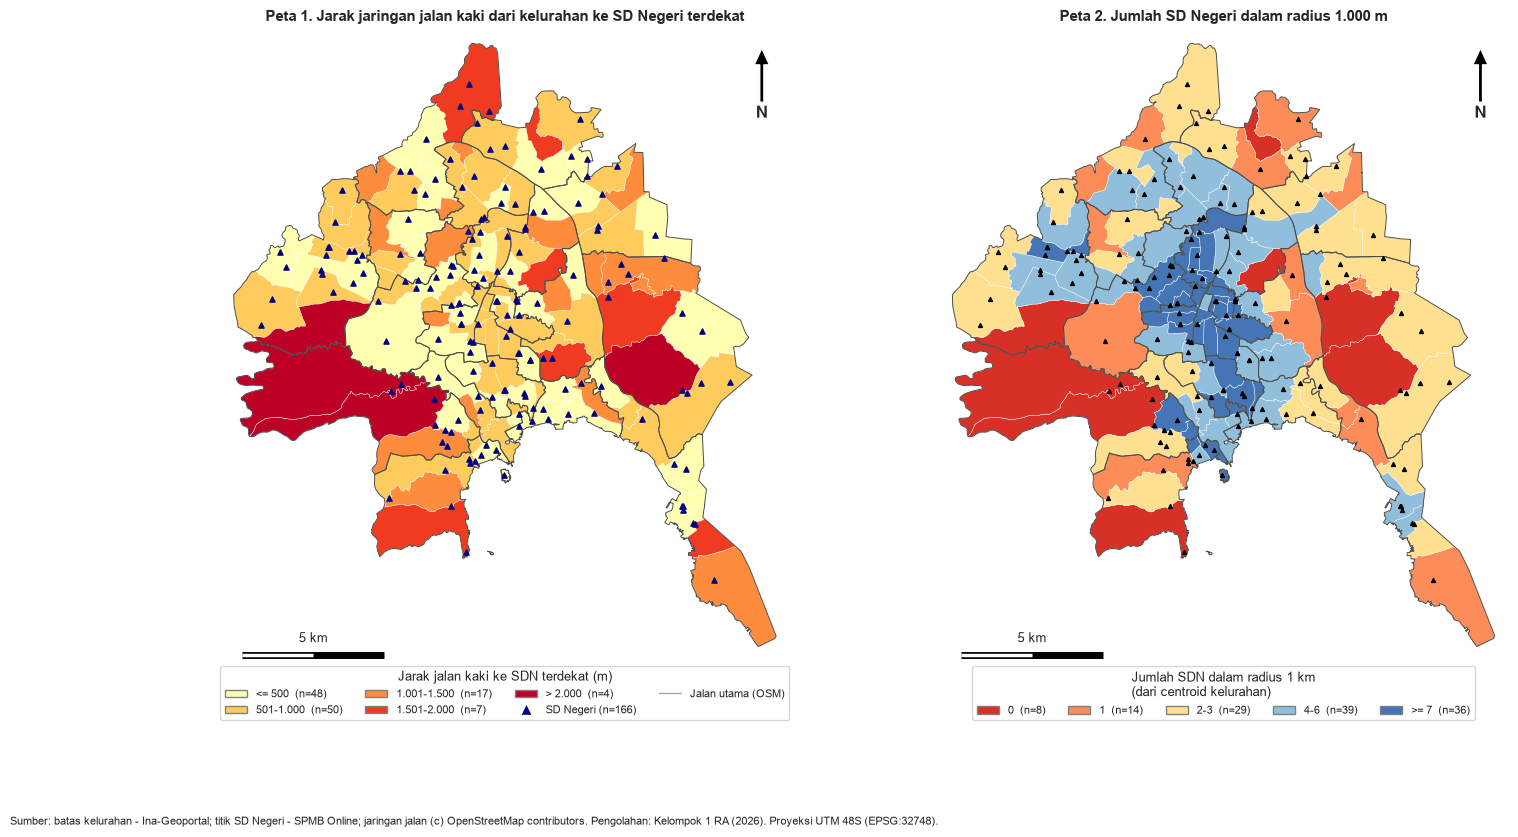

In [10]:
SUMBER = ("Sumber: batas kelurahan - Ina-Geoportal; titik SD Negeri - SPMB Online; jaringan jalan (c) OpenStreetMap contributors. "
          "Pengolahan: Kelompok 1 RA (2026). Proyeksi UTM 48S (EPSG:32748).")
kec_geo = kel.dissolve(by="kecamatan")
xmin, ymin, xmax, ymax = kel.total_bounds

edges = ox.graph_to_gdfs(Gp, nodes=False)
edges["hw"] = edges["highway"].apply(lambda v: v[0] if isinstance(v, list) else v)
jalan_utama = gpd.clip(edges[edges["hw"].isin(["trunk", "primary", "secondary", "tertiary"])], kel.union_all())


def hiasan_peta(ax, judul, bar_m=5000):
    # judul, skala batang, arah utara
    ax.set_xlim(xmin - 500, xmax + 500)
    ax.set_ylim(ymin - 500, ymax + 500)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(judul, fontsize=11, fontweight="bold")
    x0 = xmin + 300
    y0 = ymin - 300
    ax.plot([x0, x0 + bar_m], [y0, y0], color="black", lw=5, solid_capstyle="butt")
    ax.plot([x0, x0 + bar_m / 2], [y0, y0], color="white", lw=2.5, solid_capstyle="butt")
    ax.text(x0 + bar_m / 2, y0 + 450, f"{bar_m // 1000} km", ha="center", fontsize=9)
    ax.annotate("N", xy=(0.95, 0.97), xytext=(0.95, 0.86), xycoords="axes fraction", textcoords="axes fraction",
                arrowprops=dict(facecolor="black", width=3, headwidth=11), ha="center", fontsize=12, fontweight="bold")


def peta_kelas(ax, kolom, urutan, warna, judul_legenda, loc="lower right"):
    for k, c in zip(urutan, warna):
        sub = kel[kel[kolom] == k]
        if len(sub):
            sub.plot(ax=ax, color=c, edgecolor="white", linewidth=0.3)
    kec_geo.boundary.plot(ax=ax, color="0.3", linewidth=0.7)
    h = [Patch(facecolor=c, edgecolor="grey", label=f"{k}  (n={(kel[kolom] == k).sum()})") for k, c in zip(urutan, warna)]
    return h


kel["kelas_jarak"] = pd.cut(kel["jarak_m"], [0, 500, 1000, 1500, 2000, np.inf],
                            labels=["<= 500", "501-1.000", "1.001-1.500", "1.501-2.000", "> 2.000"])
kel["kelas_n1km"] = pd.cut(kel["n_sd_1km"], [-1, 0, 1, 3, 6, 100], labels=["0", "1", "2-3", "4-6", ">= 7"])
w_buruk_ke_baik = ["#d73027", "#fc8d59", "#fee090", "#91bfdb", "#4575b4"]
w_jarak = ["#ffffb2", "#fecc5c", "#fd8d3c", "#f03b20", "#bd0026"]

fig, axs = plt.subplots(1, 2, figsize=(17, 8.2))
ax = axs[0]
jalan_utama.plot(ax=ax, color="0.65", linewidth=0.4, zorder=1)
h = peta_kelas(ax, "kelas_jarak", list(kel["kelas_jarak"].cat.categories), w_jarak, "")
sd_gdf.plot(ax=ax, color="navy", marker="^", markersize=14, zorder=5)
h += [Line2D([0], [0], marker="^", color="w", markerfacecolor="navy", markersize=9, label=f"SD Negeri (n={len(sd_gdf)})"),
      Line2D([0], [0], color="0.65", lw=1, label="Jalan utama (OSM)")]
ax.legend(handles=h, title="Jarak jalan kaki ke SDN terdekat (m)", loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4,
          fontsize=8, title_fontsize=9, frameon=True)
hiasan_peta(ax, "Peta 1. Jarak jaringan jalan kaki dari kelurahan ke SD Negeri terdekat")

ax = axs[1]
h = peta_kelas(ax, "kelas_n1km", list(kel["kelas_n1km"].cat.categories), w_buruk_ke_baik, "")
sd_gdf.plot(ax=ax, color="black", marker="^", markersize=8, zorder=5)
ax.legend(handles=h, title="Jumlah SDN dalam radius 1 km\n(dari centroid kelurahan)", loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=5, fontsize=8,
          title_fontsize=9, frameon=True)
hiasan_peta(ax, "Peta 2. Jumlah SD Negeri dalam radius 1.000 m")
fig.text(0.01, -0.09, SUMBER, fontsize=8, ha="left")
fig.savefig(GAMBAR / "peta1_peta2_jarak_vs_buffer.png")
plt.show()

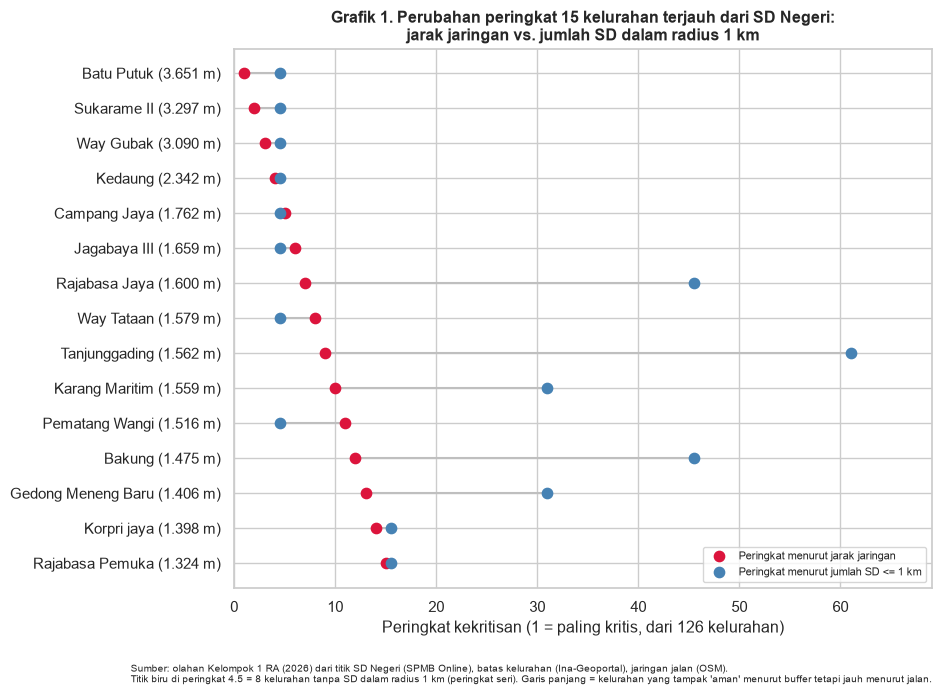

In [11]:
top = kel.nlargest(15, "jarak_m").sort_values("jarak_m")
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(top))
ax.hlines(y, top["rank_jarak"], top["rank_n1km"], color="0.75", zorder=1)
ax.scatter(top["rank_jarak"], y, color="crimson", s=55, label="Peringkat menurut jarak jaringan", zorder=3)
ax.scatter(top["rank_n1km"], y, color="steelblue", s=55, label="Peringkat menurut jumlah SD <= 1 km", zorder=3)
ax.set_yticks(y)
ax.set_yticklabels([f"{n} ({fmt(j)} m)" for n, j in zip(top["nama_des"], top["jarak_m"])])
ax.set_xlabel("Peringkat kekritisan (1 = paling kritis, dari 126 kelurahan)")
ax.set_title("Grafik 1. Perubahan peringkat 15 kelurahan terjauh dari SD Negeri:\njarak jaringan vs. jumlah SD dalam radius 1 km", fontweight="bold")
ax.set_xlim(0, kel["rank_n1km"].max() * 0.55)
ax.legend(loc="lower right", fontsize=8)
n_nol = int((kel["n_sd_1km"] == 0).sum())
fig.text(0.01, -0.025, "Sumber: olahan Kelompok 1 RA (2026) dari titik SD Negeri (SPMB Online), batas kelurahan (Ina-Geoportal), jaringan jalan (OSM).\n"
         f"Titik biru di peringkat {(n_nol + 1) / 2:.1f} = {n_nol} kelurahan tanpa SD dalam radius 1 km (peringkat seri). "
         "Garis panjang = kelurahan yang tampak 'aman' menurut buffer tetapi jauh menurut jalan.", fontsize=7)
fig.savefig(GAMBAR / "grafik1_perubahan_peringkat.png")
plt.show()

## 4. Rasio SD per 1.000 Anak dan Kepadatan Penduduk (Pertanyaan 2)

### 4.1 Pengolahan relasional (SQL) dan statistik deskriptif
Indikator per kelurahan: **kepadatan** (jiwa/km²) = penduduk ÷ luas; **rasio SD per 1.000 anak** = jumlah SD Negeri di dalam batas kelurahan ÷ anak 7–12 tahun × 1.000. Agregasi per kecamatan dijalankan dengan SQL (SQLite) agar dapat dipertanggungjawabkan sebagai olahan basis data relasional.

In [12]:
con = sqlite3.connect(":memory:")
tab = kel.drop(columns=["geometry", "kelas_jarak", "kelas_n1km"]).copy()
tab["kec_kunci"] = tab["kunci_kec"]
tab.to_sql("kelurahan", con, index=False)
bps_kec[["kunci", "kecamatan", "pop_ribu"]].to_sql("kecamatan_bps", con, index=False)

sql = '''
SELECT k.kecamatan,
       COUNT(*)                                              AS jml_kelurahan,
       ROUND(SUM(k.penduduk))                                AS penduduk,
       ROUND(SUM(k.anak_7_12))                               AS anak_7_12,
       SUM(k.n_sd)                                           AS sd_negeri,
       ROUND(SUM(k.n_sd) * 1000.0 / SUM(k.anak_7_12), 2)     AS sd_per_1000_anak,
       ROUND(SUM(k.penduduk) / SUM(k.luas_km2))              AS kepadatan_jiwa_km2,
       ROUND(AVG(k.jarak_m))                                 AS rata2_jarak_m,
       SUM(CASE WHEN k.jarak_m > 1000 THEN 1 ELSE 0 END)     AS kel_jauh_gt_1km,
       ROUND(SUM(CASE WHEN k.jarak_m > 1000 THEN k.anak_7_12 ELSE 0 END)) AS anak_di_luar_1km,
       ROUND(b.pop_ribu * 1000)                              AS penduduk_bps
FROM kelurahan k
JOIN kecamatan_bps b ON k.kec_kunci = b.kunci
GROUP BY k.kecamatan
ORDER BY anak_di_luar_1km DESC
'''
ringkas_kec = pd.read_sql(sql, con)
display(ringkas_kec)
print("Pemeriksaan: selisih penduduk hasil agregasi vs BPS per kecamatan (maks, jiwa):",
      float((ringkas_kec["penduduk"] - ringkas_kec["penduduk_bps"]).abs().max()))

,kecamatan,jml_kelurahan,penduduk,anak_7_12,sd_negeri,sd_per_1000_anak,kepadatan_jiwa_km2,rata2_jarak_m,kel_jauh_gt_1km,anak_di_luar_1km,penduduk_bps
0,Sukabumi,7,73700.0,7916.0,11,1.39,2939.0,1291.0,5,5415.0,73700.0
1,Panjang,8,72000.0,7733.0,10,1.29,5286.0,695.0,2,3357.0,72000.0
2,Teluk Betung Barat,5,39000.0,4189.0,9,2.15,1906.0,1893.0,3,3335.0,39000.0
3,Way Halim,6,66900.0,7186.0,6,0.84,10762.0,729.0,2,2950.0,66900.0
4,Rajabasa,7,56700.0,6090.0,9,1.48,4407.0,897.0,3,2396.0,56700.0
5,Tanjung Karang Barat,7,62200.0,6681.0,14,2.10,5559.0,646.0,1,1605.0,62200.0
6,Kedamaian,7,52700.0,5660.0,6,1.06,6330.0,753.0,2,1582.0,52700.0
7,Langkapura,5,43900.0,4715.0,3,0.64,8034.0,698.0,1,1426.0,43900.0
8,Bumi Waras,5,56400.0,6058.0,8,1.32,12463.0,422.0,1,1386.0,56400.0
9,Tanjung Karang Pusat,7,49000.0,5263.0,8,1.52,13595.0,516.0,1,632.0,49000.0


Pemeriksaan: selisih penduduk hasil agregasi vs BPS per kecamatan (maks, jiwa): 0.0


,count,mean,std,min,25%,50%,75%,max
luas_km2,126.0,1.46,1.55,0.13,0.52,1.04,1.70,10.29
penduduk,126.0,8638.10,6309.24,205.38,4692.01,7143.42,11853.77,33485.01
anak_7_12,126.0,927.79,677.66,22.06,503.96,767.26,1273.18,3596.53
kepadatan,126.0,9639.64,7806.07,662.80,3884.03,8184.94,12496.05,42360.19
n_sd,126.0,1.32,1.20,0.00,1.00,1.00,2.00,7.00
rasio_sd_1000,126.0,2.11,4.43,0.00,0.30,1.27,2.44,45.33
jarak_m,126.0,758.51,581.75,67.27,373.33,645.24,942.66,3651.39
n_sd_1km,126.0,4.46,2.85,0.00,2.00,4.00,7.00,11.00


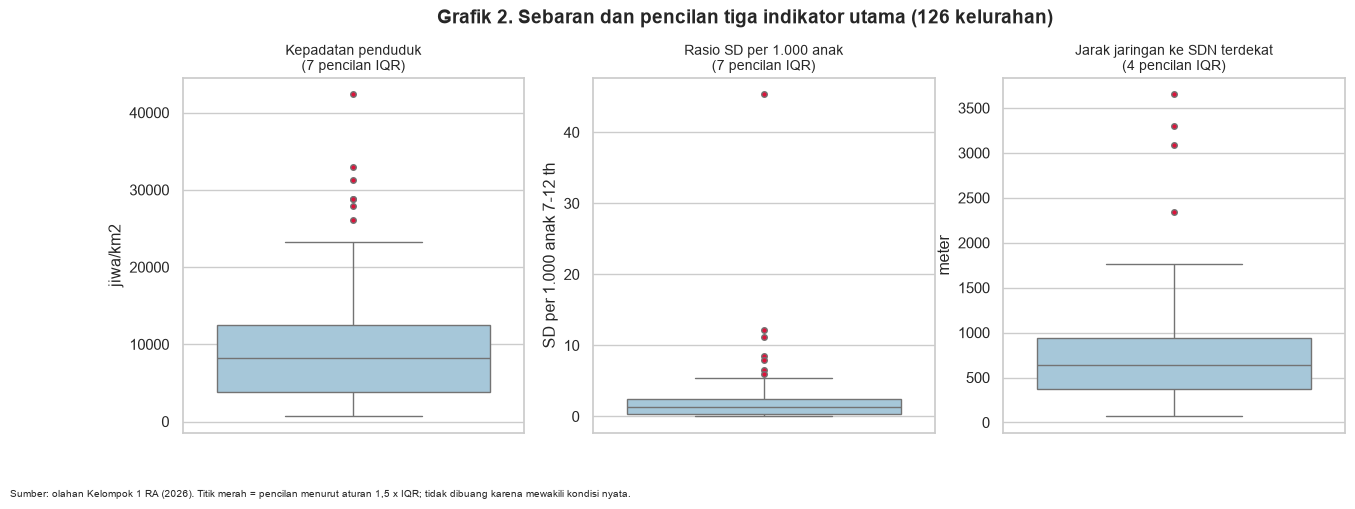

,nama_des,kecamatan,anak_7_12,n_sd,rasio_sd_1000,kepadatan
110,Tanjungagung Raya,Kedamaian,22.1,1,45.3,1619.2
88,Kota Sepang,Labuhan Ratu,163.7,2,12.2,2711.4
15,Susunan Baru,Tanjung Karang Barat,178.0,2,11.2,2024.5
18,Sukajawa Baru,Tanjung Karang Barat,236.1,2,8.5,8035.2
67,Perumnas Way Kandis,Tanjung Senang,380.3,3,7.9,4806.3
76,Sumber Rejo,Kemiling,765.5,5,6.5,6827.4
103,Pelita,Enggal,166.9,1,6.0,5716.8


In [13]:
kolom_desk = ["luas_km2", "penduduk", "anak_7_12", "kepadatan", "n_sd", "rasio_sd_1000", "jarak_m", "n_sd_1km"]
desk = kel[kolom_desk].describe().T.round(2)
display(desk)

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (kol, jdl, sat) in zip(axs, [("kepadatan", "Kepadatan penduduk", "jiwa/km2"),
                                     ("rasio_sd_1000", "Rasio SD per 1.000 anak", "SD per 1.000 anak 7-12 th"),
                                     ("jarak_m", "Jarak jaringan ke SDN terdekat", "meter")]):
    sns.boxplot(y=kel[kol], ax=ax, color="#9ecae1", flierprops=dict(marker="o", markerfacecolor="crimson", markersize=4))
    ax.set_title(f"{jdl}\n({int(outlier_iqr(kel[kol]).sum())} pencilan IQR)", fontsize=10)
    ax.set_ylabel(sat)
    ax.set_xlabel("")
fig.suptitle("Grafik 2. Sebaran dan pencilan tiga indikator utama (126 kelurahan)", fontweight="bold", y=1.03)
fig.text(0.01, -0.03, "Sumber: olahan Kelompok 1 RA (2026). Titik merah = pencilan menurut aturan 1,5 x IQR; tidak dibuang karena mewakili kondisi nyata.", fontsize=7)
fig.savefig(GAMBAR / "grafik2_boxplot_indikator.png")
plt.show()

out_r = kel[outlier_iqr(kel["rasio_sd_1000"])].sort_values("rasio_sd_1000", ascending=False)
display(out_r[["nama_des", "kecamatan", "anak_7_12", "n_sd", "rasio_sd_1000", "kepadatan"]].round(1).head(8))

**Catatan pencilan rasio.** Rasio tertinggi muncul pada kelurahan dengan estimasi anak sangat sedikit (penyebut kecil) tetapi memiliki sekolah — lonjakan ini adalah efek penyebut kecil, bukan kelimpahan layanan. Karena itu uji korelasi utama memakai **Spearman (berbasis peringkat, tahan pencilan)** dan Pearson hanya pada data ber-logaritma sebagai pembanding.

### 4.2 Uji normalitas dan korelasi
*H₀*: tidak ada hubungan monotonik antara kepadatan penduduk dan rasio SD per 1.000 anak. Tingkat signifikansi α = 0,05.

In [14]:
sw = pd.DataFrame({
    "variabel": ["kepadatan", "log(kepadatan)", "rasio SD/1000 anak", "log(1+rasio)"],
    "W Shapiro-Wilk": [stats.shapiro(v).statistic for v in (kel["kepadatan"], np.log(kel["kepadatan"]),
                                                              kel["rasio_sd_1000"], np.log1p(kel["rasio_sd_1000"]))],
    "p-value": [stats.shapiro(v).pvalue for v in (kel["kepadatan"], np.log(kel["kepadatan"]),
                                                  kel["rasio_sd_1000"], np.log1p(kel["rasio_sd_1000"]))],
}).round(4)
sw["normal (p>0,05)?"] = np.where(sw["p-value"] > 0.05, "ya", "tidak")
display(sw)

rho, p_rho = stats.spearmanr(kel["kepadatan"], kel["rasio_sd_1000"])
r, p_r = stats.pearsonr(np.log(kel["kepadatan"]), np.log1p(kel["rasio_sd_1000"]))
rho_n, p_n = stats.spearmanr(kel["kepadatan"], kel["n_sd"])
rho_b, p_b = stats.spearmanr(kel["kepadatan"], kel["n_sd_1km"])
rho_j, p_j = stats.spearmanr(kel["kepadatan"], kel["jarak_m"])
korelasi = pd.DataFrame({
    "pasangan variabel": ["kepadatan vs rasio SD/1000 anak (utama)", "log kepadatan vs log(1+rasio) (Pearson)",
                          "kepadatan vs jumlah SD dalam kelurahan", "kepadatan vs jumlah SD <= 1 km",
                          "kepadatan vs jarak jaringan ke SDN"],
    "koefisien": [rho, r, rho_n, rho_b, rho_j],
    "p-value": [p_rho, p_r, p_n, p_b, p_j],
}).round(4)
korelasi["signifikan (a=0,05)?"] = np.where(korelasi["p-value"] < 0.05, "ya", "tidak")
display(korelasi)

def kata(p, c):
    arah = "negatif" if c < 0 else "positif"
    kuat = "sangat lemah" if abs(c) < 0.2 else "lemah" if abs(c) < 0.4 else "sedang" if abs(c) < 0.6 else "kuat"
    return f"{kuat} {arah}", ("signifikan" if p < 0.05 else "tidak signifikan pada α = 5%")

k1, s1 = kata(p_rho, rho)
k2, s2 = kata(p_b, rho_b)
k3, s3 = kata(p_j, rho_j)
md_out(f"**Hasil P2.** Hubungan kepadatan penduduk dengan rasio SD per 1.000 anak bersifat **{k1}** "
       f"(Spearman ρ = {rho:.2f}, p = {p_rho:.3f}; {s1}). Pearson pada data ber-logaritma memberi r = {r:.2f} (p = {p_r:.3f}). "
       f"Jumlah SD di dalam kelurahan nyaris tidak berkaitan dengan kepadatan (ρ = {rho_n:.2f}, p = {p_n:.2f}), artinya penambahan SD tidak mengikuti kepadatan penduduk. "
       f"Namun kelurahan yang lebih padat cenderung memiliki lebih banyak SD dalam radius 1 km (ρ = {rho_b:.2f}; {k2}, {s2}) dan lebih dekat ke SD "
       f"(kepadatan vs jarak: ρ = {rho_j:.2f}; {k3}, {s3}). "
       f"**Kehati-hatian interpretasi:** rasio memuat anak 7–12 tahun di penyebut, dan anak diestimasi dari penduduk = kepadatan × luas, "
       f"sehingga ada keterkaitan matematis bawaan antara rasio dan kepadatan; itulah sebabnya korelasi dengan jumlah SD dan jarak ditampilkan sebagai pembanding.")

,variabel,W Shapiro-Wilk,p-value,"normal (p>0,05)?"
0,kepadatan,0.8679,0.0000,tidak
1,log(kepadatan),0.9762,0.0254,tidak
2,rasio SD/1000 anak,0.3809,0.0000,tidak
3,log(1+rasio),0.9147,0.0000,tidak


,pasangan variabel,koefisien,p-value,"signifikan (a=0,05)?"
0,kepadatan vs rasio SD/1000 anak (utama),-0.1722,0.0538,tidak
1,log kepadatan vs log(1+rasio) (Pearson),-0.2011,0.0240,ya
2,kepadatan vs jumlah SD dalam kelurahan,-0.0250,0.7813,tidak
3,kepadatan vs jumlah SD <= 1 km,0.5827,0.0000,ya
4,kepadatan vs jarak jaringan ke SDN,-0.3554,0.0000,ya


**Hasil P2.** Hubungan kepadatan penduduk dengan rasio SD per 1.000 anak bersifat **sangat lemah negatif** (Spearman ρ = -0.17, p = 0.054; tidak signifikan pada α = 5%). Pearson pada data ber-logaritma memberi r = -0.20 (p = 0.024). Jumlah SD di dalam kelurahan nyaris tidak berkaitan dengan kepadatan (ρ = -0.02, p = 0.78), artinya penambahan SD tidak mengikuti kepadatan penduduk. Namun kelurahan yang lebih padat cenderung memiliki lebih banyak SD dalam radius 1 km (ρ = 0.58; sedang positif, signifikan) dan lebih dekat ke SD (kepadatan vs jarak: ρ = -0.36; lemah negatif, signifikan). **Kehati-hatian interpretasi:** rasio memuat anak 7–12 tahun di penyebut, dan anak diestimasi dari penduduk = kepadatan × luas, sehingga ada keterkaitan matematis bawaan antara rasio dan kepadatan; itulah sebabnya korelasi dengan jumlah SD dan jarak ditampilkan sebagai pembanding.

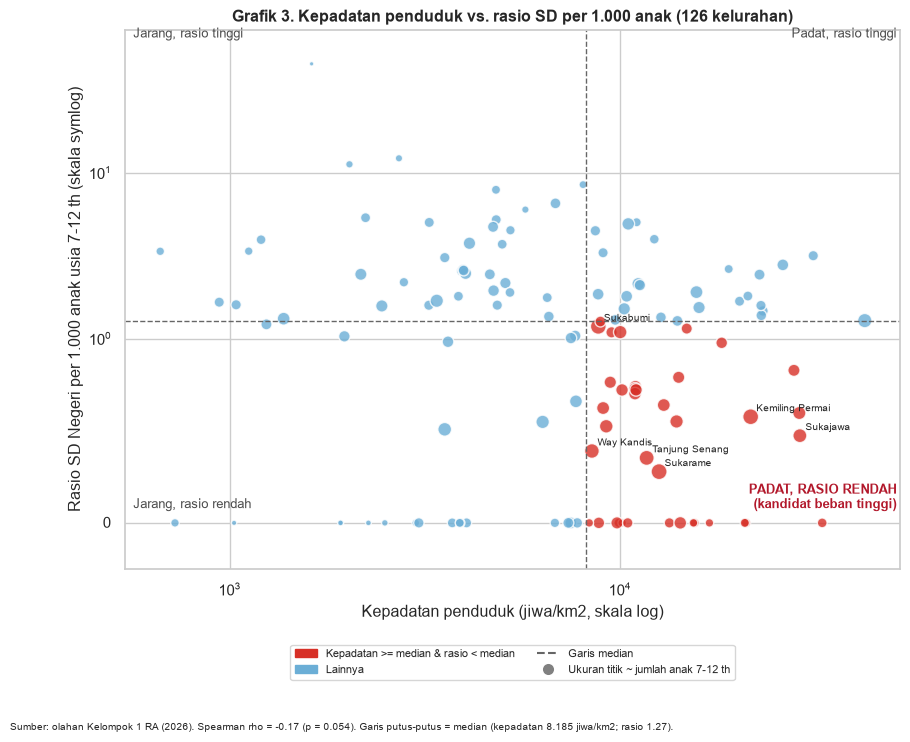

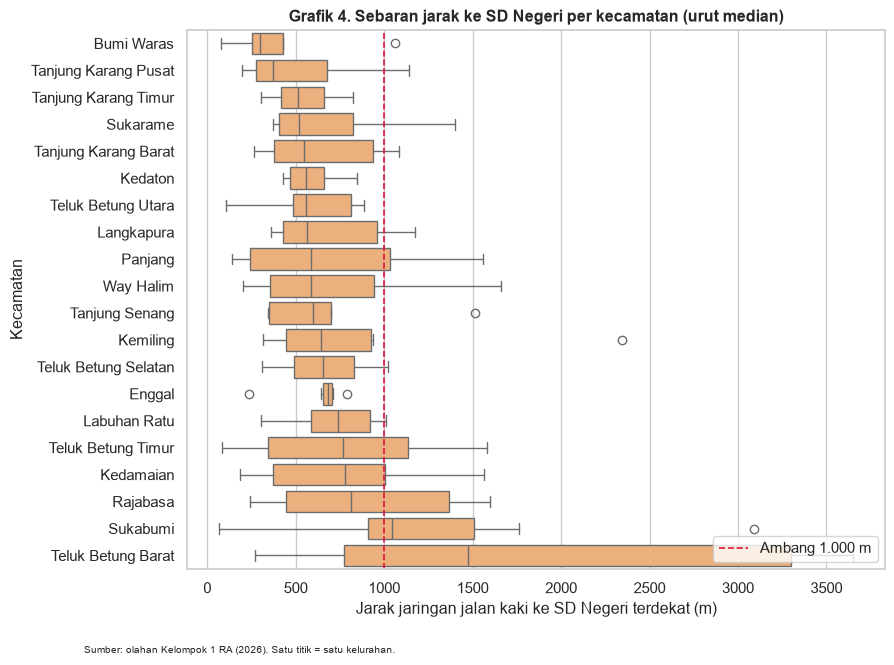

In [15]:
fig, ax = plt.subplots(figsize=(10, 7))
med_x, med_y = kel["kepadatan"].median(), kel["rasio_sd_1000"].median()
warna = np.where((kel["kepadatan"] >= med_x) & (kel["rasio_sd_1000"] < med_y), "#d73027", "#6baed6")
ax.scatter(kel["kepadatan"], kel["rasio_sd_1000"], c=warna, s=np.sqrt(kel["anak_7_12"]) * 2.2, alpha=0.8, edgecolor="white")
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1)
ax.axvline(med_x, color="0.4", ls="--", lw=1)
ax.axhline(med_y, color="0.4", ls="--", lw=1)
ax.set_xlabel("Kepadatan penduduk (jiwa/km2, skala log)")
ax.set_ylabel("Rasio SD Negeri per 1.000 anak usia 7-12 th (skala symlog)")
ax.set_title("Grafik 3. Kepadatan penduduk vs. rasio SD per 1.000 anak (126 kelurahan)", fontweight="bold")
ax.set_ylim(-0.25, kel["rasio_sd_1000"].max() * 1.6)
ya, xa = ax.get_ylim()[1], ax.get_xlim()[1]
ax.text(xa * 0.98, ya * 0.9, "Padat, rasio tinggi", ha="right", fontsize=9, color="0.3")
ax.text(xa * 0.98, 0.08, "PADAT, RASIO RENDAH\n(kandidat beban tinggi)", ha="right", fontsize=9, color="#b2182b", fontweight="bold")
ax.text(ax.get_xlim()[0] * 1.05, ya * 0.9, "Jarang, rasio tinggi", ha="left", fontsize=9, color="0.3")
ax.text(ax.get_xlim()[0] * 1.05, 0.08, "Jarang, rasio rendah", ha="left", fontsize=9, color="0.3")
lab = kel[(kel["kepadatan"] >= med_x) & (kel["rasio_sd_1000"] < med_y)].nlargest(6, "anak_7_12")
for _, b in lab.iterrows():
    ax.annotate(b["nama_des"], (b["kepadatan"], b["rasio_sd_1000"]), fontsize=7.5, xytext=(4, 4), textcoords="offset points")
ax.legend(handles=[Patch(color="#d73027", label="Kepadatan >= median & rasio < median"), Patch(color="#6baed6", label="Lainnya"),
                   Line2D([0], [0], color="0.4", ls="--", label="Garis median"),
                   Line2D([0], [0], marker="o", color="w", markerfacecolor="grey", markersize=9, label="Ukuran titik ~ jumlah anak 7-12 th")],
          loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=8)
fig.text(0.01, -0.12, f"Sumber: olahan Kelompok 1 RA (2026). Spearman rho = {rho:.2f} (p = {p_rho:.3f}). Garis putus-putus = median (kepadatan {fmt(med_x)} jiwa/km2; rasio {med_y:.2f}).", fontsize=7)
fig.savefig(GAMBAR / "grafik3_scatter_kepadatan_rasio.png")
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
urut = kel.groupby("kecamatan")["jarak_m"].median().sort_values().index
sns.boxplot(data=kel, y="kecamatan", x="jarak_m", order=urut, ax=ax, color="#fdae6b")
ax.axvline(AMBANG_JARAK_M, color="crimson", ls="--", lw=1.2, label="Ambang 1.000 m")
ax.set_xlabel("Jarak jaringan jalan kaki ke SD Negeri terdekat (m)")
ax.set_ylabel("Kecamatan")
ax.set_title("Grafik 4. Sebaran jarak ke SD Negeri per kecamatan (urut median)", fontweight="bold")
ax.legend(loc="lower right")
fig.text(0.01, -0.01, "Sumber: olahan Kelompok 1 RA (2026). Satu titik = satu kelurahan.", fontsize=7)
fig.savefig(GAMBAR / "grafik4_jarak_per_kecamatan.png")
plt.show()

## 5. Pengelompokan Kelurahan dan Penentuan Prioritas (Pertanyaan 3)

### 5.1 Metode: *K-Means* pada empat indikator
**Mengapa *K-Means*?** Tujuannya mengelompokkan 126 kelurahan menjadi tipologi layanan berdasarkan beberapa indikator numerik sekaligus; *K-Means* sederhana, dapat dijelaskan, dan sesuai untuk data numerik yang telah distandarisasi.
**Asumsi dan perlakuan data.**
* Fitur: (1) jarak jaringan ke SDN terdekat, (2) jumlah SDN dalam radius 1 km, (3) rasio SD per 1.000 anak, (4) jumlah anak 7–12 tahun.
* Jarak, rasio, dan jumlah anak sangat miring ke kanan, sehingga ditransformasi $\log(1+x)$; seluruh fitur kemudian di-*z-score* (`StandardScaler`) agar satuan meter tidak mendominasi.
* *K-Means* mengasumsikan klaster kira-kira bulat dan berukuran sebanding; jumlah klaster $k$ dipilih dengan *elbow* (inersia) dan *silhouette score*, lalu diuji kebermaknaan perencanaannya.

,k,inersia,silhouette
0,2,379.168,0.226
1,3,304.840,0.253
2,4,252.101,0.253
3,5,216.025,0.276
4,6,191.841,0.269
5,7,169.299,0.256
6,8,147.589,0.279


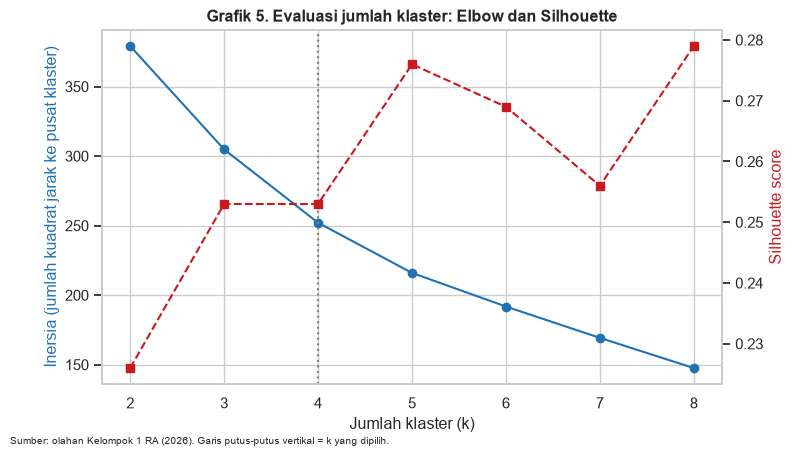

In [16]:
fitur_asli = ["jarak_m", "n_sd_1km", "rasio_sd_1000", "anak_7_12"]
X = pd.DataFrame({"log_jarak": np.log1p(kel["jarak_m"]), "n_sd_1km": kel["n_sd_1km"],
                  "log_rasio": np.log1p(kel["rasio_sd_1000"]), "log_anak": np.log1p(kel["anak_7_12"])})
Z = StandardScaler().fit_transform(X)

evaluasi = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    evaluasi.append({"k": k, "inersia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_)})
evaluasi = pd.DataFrame(evaluasi).round(3)
display(evaluasi)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(evaluasi["k"], evaluasi["inersia"], "o-", color="#2171b5")
ax.set_xlabel("Jumlah klaster (k)")
ax.set_ylabel("Inersia (jumlah kuadrat jarak ke pusat klaster)", color="#2171b5")
ax2 = ax.twinx()
ax2.plot(evaluasi["k"], evaluasi["silhouette"], "s--", color="#cb181d")
ax2.set_ylabel("Silhouette score", color="#cb181d")
ax2.grid(False)
ax.axvline(4, color="0.5", ls=":")
ax.set_title("Grafik 5. Evaluasi jumlah klaster: Elbow dan Silhouette", fontweight="bold")
fig.text(0.01, -0.02, "Sumber: olahan Kelompok 1 RA (2026). Garis putus-putus vertikal = k yang dipilih.", fontsize=7)
fig.savefig(GAMBAR / "grafik5_elbow_silhouette.png")
plt.show()

,jumlah_kelurahan,jarak_rata2_m,sd_dalam_1km,rasio_sd_per_1000,anak_per_kelurahan,kepadatan,total_anak
klaster,,,,,,,
A. Kritis jangkauan (jauh dari SD),33,1389.7,1.8,1.2,1334.3,6061.5,44031.5
"B. Padat, beban tinggi (SD dekat)",42,379.0,4.2,1.3,1138.0,11360.6,47794.8
C. Terlayani baik,29,538.6,6.9,5.9,593.0,11032.0,17195.9
"D. Tanpa SD di dalam batas, dilayani SD sekitar",22,826.2,5.9,0.0,358.2,9886.1,7880.0


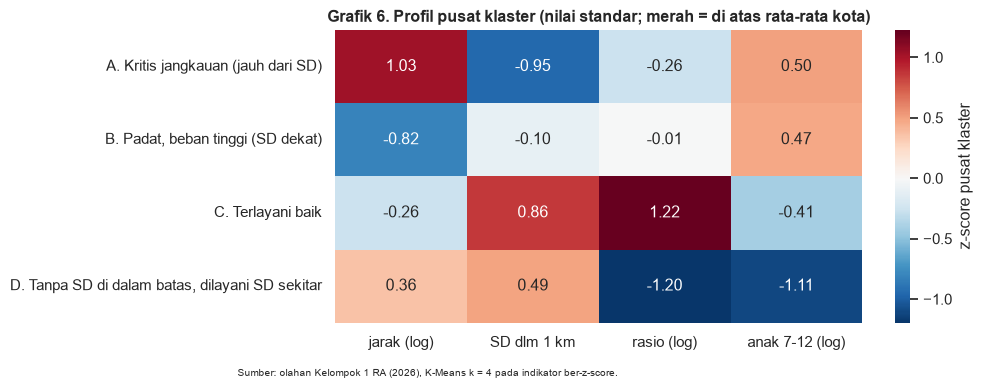

**Pemilihan *k* dan kualitas klaster.** Inersia menurun tajam sampai k ≈ 4 lalu melandai (*elbow*); silhouette k = 4 bernilai **0.25**, sedangkan maksimum 0.28 dicapai pada k = 8. Karena selisihnya kecil dan k = 4 menghasilkan empat tipologi yang masing-masing memiliki makna intervensi berbeda, dipilih **k = 4**. Silhouette di bawah 0,3 menandakan struktur klaster **lemah–sedang** (kelurahan tersebar kontinu, bukan kelompok yang terpisah tegas), sehingga klaster dipakai sebagai *tipologi indikatif* dan bukan batas mutlak; keputusan prioritas tetap memakai ambang jarak yang eksplisit (Bab 5.2).

In [17]:
K_PILIH = 4
km = KMeans(n_clusters=K_PILIH, n_init=20, random_state=RANDOM_STATE).fit(Z)
kel["klaster_id"] = km.labels_
sil_k = float(evaluasi.loc[evaluasi["k"] == K_PILIH, "silhouette"].iloc[0])
sil_maks = evaluasi.loc[evaluasi["silhouette"].idxmax()]

prof = kel.groupby("klaster_id")[["jarak_m", "n_sd_1km", "rasio_sd_1000", "anak_7_12", "kepadatan"]].mean()
sisa = set(prof.index)
label = {}
c = prof.loc[list(sisa), "jarak_m"].idxmax();       label[c] = "A. Kritis jangkauan (jauh dari SD)";            sisa.remove(c)
c = prof.loc[list(sisa), "anak_7_12"].idxmax();     label[c] = "B. Padat, beban tinggi (SD dekat)";            sisa.remove(c)
c = prof.loc[list(sisa), "rasio_sd_1000"].idxmax(); label[c] = "C. Terlayani baik";                            sisa.remove(c)
label[sisa.pop()] = "D. Tanpa SD di dalam batas, dilayani SD sekitar"
kel["klaster"] = kel["klaster_id"].map(label)

profil = kel.groupby("klaster").agg(jumlah_kelurahan=("kode", "size"), jarak_rata2_m=("jarak_m", "mean"),
                                    sd_dalam_1km=("n_sd_1km", "mean"), rasio_sd_per_1000=("rasio_sd_1000", "mean"),
                                    anak_per_kelurahan=("anak_7_12", "mean"), kepadatan=("kepadatan", "mean"),
                                    total_anak=("anak_7_12", "sum")).round(1)
display(profil)

pusat = pd.DataFrame(km.cluster_centers_, columns=["jarak (log)", "SD dlm 1 km", "rasio (log)", "anak 7-12 (log)"],
                     index=[label[i] for i in range(K_PILIH)]).sort_index()
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sns.heatmap(pusat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "z-score pusat klaster"})
ax.set_title("Grafik 6. Profil pusat klaster (nilai standar; merah = di atas rata-rata kota)", fontweight="bold")
fig.text(0.01, -0.03, "Sumber: olahan Kelompok 1 RA (2026), K-Means k = 4 pada indikator ber-z-score.", fontsize=7)
fig.savefig(GAMBAR / "grafik6_profil_klaster.png")
plt.show()

md_out(f"**Pemilihan *k* dan kualitas klaster.** Inersia menurun tajam sampai k ≈ 4 lalu melandai (*elbow*); silhouette k = {K_PILIH} bernilai **{sil_k:.2f}**, "
       f"sedangkan maksimum {sil_maks['silhouette']:.2f} dicapai pada k = {int(sil_maks['k'])}. Karena selisihnya kecil dan k = 4 menghasilkan empat tipologi yang masing-masing "
       f"memiliki makna intervensi berbeda, dipilih **k = {K_PILIH}**. Silhouette di bawah 0,3 menandakan struktur klaster **lemah–sedang** (kelurahan tersebar kontinu, bukan kelompok yang terpisah tegas), "
       f"sehingga klaster dipakai sebagai *tipologi indikatif* dan bukan batas mutlak; keputusan prioritas tetap memakai ambang jarak yang eksplisit (Bab 5.2).")

### 5.2 Aturan prioritas intervensi
Klaster saja tidak cukup untuk memutuskan lokasi, sehingga prioritas dirumuskan dengan **aturan eksplisit dan dapat diaudit**:

| Intervensi | Syarat | Alasan |
|---|---|---|
| **USB prioritas 1** (unit sekolah baru) | jarak jaringan > 1.000 m **dan** klaster A **dan** jumlah anak ≥ median kota; diurutkan menurut *anak-km di atas ambang* = anak × (jarak − 1.000 m) / 1.000 | anak jauh dari SD, dikonfirmasi pola klaster, dan kohort cukup besar untuk membenarkan investasi sekolah; urutan memberi bobot pada kelurahan yang jauh *dan* berpenduduk anak banyak |
| **Alternatif non-bangunan** (angkutan/rute aman, SD satelit) | jarak jaringan > 1.000 m tetapi tidak memenuhi syarat USB-1 | jauh namun kohort kecil — sekolah baru kurang efisien |
| **RKB prioritas** (tambah ruang kelas) | jarak ≤ 1.000 m **dan** klaster B **dan** rasio SD < median | SD dekat tetapi melayani banyak anak per sekolah; peringkat memakai beban = anak ÷ jumlah SD dalam 1 km |

In [18]:
med_anak = kel["anak_7_12"].median()
med_rasio = kel["rasio_sd_1000"].median()
A = kel["klaster"].str.startswith("A")
B = kel["klaster"].str.startswith("B")
kel["beban_anak_per_sd_1km"] = kel["anak_7_12"] / kel["n_sd_1km"].replace(0, np.nan)
kel["anak_km_di_atas_ambang"] = kel["anak_7_12"] * (kel["jarak_m"] - AMBANG_JARAK_M).clip(lower=0) / 1000

jauh_m = kel["jarak_m"] > AMBANG_JARAK_M
kel["prioritas"] = "Lainnya"
kel.loc[jauh_m, "prioritas"] = "Alternatif non-bangunan (jauh, anak sedikit)"
kel.loc[jauh_m & A & (kel["anak_7_12"] >= med_anak), "prioritas"] = "USB prioritas 1"
kel.loc[(~jauh_m) & B & (kel["rasio_sd_1000"] < med_rasio), "prioritas"] = "RKB prioritas"

usb = kel[kel["prioritas"] == "USB prioritas 1"].sort_values("anak_km_di_atas_ambang", ascending=False)
rkb = kel[kel["prioritas"] == "RKB prioritas"].sort_values("beban_anak_per_sd_1km", ascending=False)
alt = kel[kel["prioritas"].str.startswith("Alternatif")].sort_values("jarak_m", ascending=False)
print("Jumlah kelurahan per kategori prioritas:")
display(kel["prioritas"].value_counts().rename("jumlah").to_frame())

kolom_usb = ["nama_des", "kecamatan", "jarak_m", "n_sd_1km", "anak_7_12", "kepadatan", "klaster"]
print("USB prioritas 1 (urut anak-km di atas ambang):")
display(usb[kolom_usb[:5] + ["anak_km_di_atas_ambang"] + kolom_usb[5:]].round(0).reset_index(drop=True))
print("RKB prioritas (urut beban anak per SD dalam 1 km):")
display(rkb[["nama_des", "kecamatan", "jarak_m", "n_sd_1km", "anak_7_12", "beban_anak_per_sd_1km", "rasio_sd_1000", "klaster"]].round(1).head(12).reset_index(drop=True))
print("Alternatif non-bangunan (jauh, anak sedikit):")
display(alt[kolom_usb].round(0).reset_index(drop=True))

Jumlah kelurahan per kategori prioritas:


,jumlah
prioritas,
Lainnya,79
RKB prioritas,19
"Alternatif non-bangunan (jauh, anak sedikit)",14
USB prioritas 1,14


USB prioritas 1 (urut anak-km di atas ambang):


,nama_des,kecamatan,jarak_m,n_sd_1km,anak_7_12,anak_km_di_atas_ambang,kepadatan,klaster
0,Batu Putuk,Teluk Betung Barat,3651.0,0,1517.0,4023.0,1373.0,A. Kritis jangkauan (jauh dari SD)
1,Rajabasa Jaya,Rajabasa,1600.0,3,1775.0,1064.0,3389.0,A. Kritis jangkauan (jauh dari SD)
2,Karang Maritim,Panjang,1559.0,2,1386.0,775.0,10113.0,A. Kritis jangkauan (jauh dari SD)
3,Jagabaya III,Way Halim,1659.0,0,1121.0,739.0,7469.0,A. Kritis jangkauan (jauh dari SD)
4,Campang Jaya,Sukabumi,1762.0,0,969.0,738.0,1965.0,A. Kritis jangkauan (jauh dari SD)
5,Srengsem,Panjang,1305.0,1,1970.0,601.0,3552.0,A. Kritis jangkauan (jauh dari SD)
6,Bakung,Teluk Betung Barat,1475.0,3,1214.0,577.0,4018.0,A. Kritis jangkauan (jauh dari SD)
7,Tanjunggading,Kedamaian,1562.0,4,777.0,437.0,3972.0,A. Kritis jangkauan (jauh dari SD)
8,Langkapura,Langkapura,1177.0,1,1426.0,252.0,10917.0,A. Kritis jangkauan (jauh dari SD)
9,Sukabumi,Sukabumi,1044.0,2,3379.0,150.0,8791.0,A. Kritis jangkauan (jauh dari SD)


RKB prioritas (urut beban anak per SD dalam 1 km):


,nama_des,kecamatan,jarak_m,n_sd_1km,anak_7_12,beban_anak_per_sd_1km,rasio_sd_1000,klaster
0,Tanjung Senang,Tanjung Senang,343.5,1,2835.4,2835.4,0.4,"B. Padat, beban tinggi (SD dekat)"
1,Kalibalau Kencana,Kedamaian,183.0,1,992.8,992.8,1.0,"B. Padat, beban tinggi (SD dekat)"
2,Sukadana Ham,Tanjung Karang Barat,434.4,1,821.0,821.0,1.2,"B. Padat, beban tinggi (SD dekat)"
3,Gunungterang,Langkapura,429.1,2,1516.5,758.3,0.7,"B. Padat, beban tinggi (SD dekat)"
4,Rajabasa,Rajabasa,455.8,3,1817.2,605.7,0.6,"B. Padat, beban tinggi (SD dekat)"
5,Sukarame Baru,Sukarame,376.5,2,1017.6,508.8,1.0,"B. Padat, beban tinggi (SD dekat)"
6,Gunungsulah,Way Halim,520.1,4,1564.1,391.0,0.6,"B. Padat, beban tinggi (SD dekat)"
7,Sepang Jaya,Labuhan Ratu,669.2,4,1374.3,343.6,0.7,"B. Padat, beban tinggi (SD dekat)"
8,Durian Payung,Tanjung Karang Pusat,372.3,4,1310.7,327.7,0.8,"B. Padat, beban tinggi (SD dekat)"
9,Kangkung,Bumi Waras,76.0,4,1208.2,302.0,0.8,"B. Padat, beban tinggi (SD dekat)"


Alternatif non-bangunan (jauh, anak sedikit):


,nama_des,kecamatan,jarak_m,n_sd_1km,anak_7_12,kepadatan,klaster
0,Sukarame II,Teluk Betung Barat,3297.0,0,604.0,939.0,A. Kritis jangkauan (jauh dari SD)
1,Way Gubak,Sukabumi,3090.0,0,626.0,1037.0,A. Kritis jangkauan (jauh dari SD)
2,Kedaung,Kemiling,2342.0,0,292.0,723.0,A. Kritis jangkauan (jauh dari SD)
3,Way Tataan,Teluk Betung Timur,1579.0,0,298.0,663.0,A. Kritis jangkauan (jauh dari SD)
4,Pematang Wangi,Tanjung Senang,1516.0,0,437.0,3892.0,A. Kritis jangkauan (jauh dari SD)
5,Gedong Meneng Baru,Rajabasa,1406.0,2,46.0,1025.0,"D. Tanpa SD di dalam batas, dilayani SD sekitar"
6,Korpri jaya,Sukarame,1398.0,1,546.0,3714.0,A. Kritis jangkauan (jauh dari SD)
7,Rajabasa Pemuka,Rajabasa,1324.0,1,576.0,4041.0,A. Kritis jangkauan (jauh dari SD)
8,Nusantara Permai,Sukabumi,1249.0,1,66.0,2264.0,"D. Tanpa SD di dalam batas, dilayani SD sekitar"
9,Sukamaju,Teluk Betung Timur,1215.0,2,297.0,1117.0,A. Kritis jangkauan (jauh dari SD)


### 5.3 Peta tipologi klaster dan lokasi prioritas

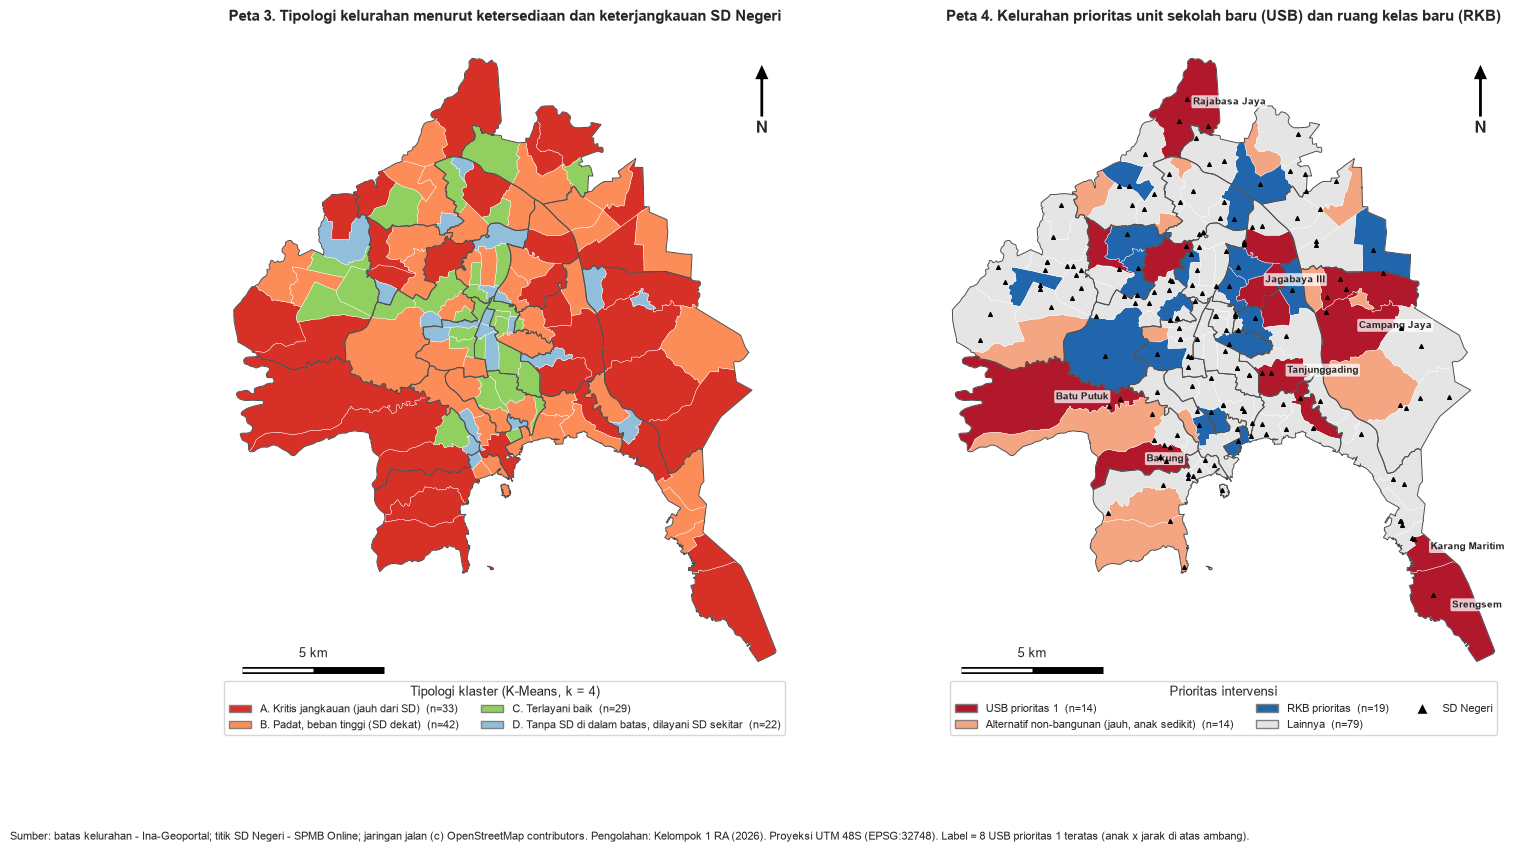

In [19]:
warna_klaster = {"A. Kritis jangkauan (jauh dari SD)": "#d73027", "B. Padat, beban tinggi (SD dekat)": "#fc8d59",
                 "C. Terlayani baik": "#91cf60", "D. Tanpa SD di dalam batas, dilayani SD sekitar": "#91bfdb"}
warna_prior = {"USB prioritas 1": "#b2182b", "Alternatif non-bangunan (jauh, anak sedikit)": "#f4a582",
               "RKB prioritas": "#2166ac", "Lainnya": "#e5e5e5"}

fig, axs = plt.subplots(1, 2, figsize=(17, 8.2))
ax = axs[0]
h = peta_kelas(ax, "klaster", list(warna_klaster), list(warna_klaster.values()), "")
ax.legend(handles=h, title="Tipologi klaster (K-Means, k = 4)", loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2,
          fontsize=8, title_fontsize=9, frameon=True)
hiasan_peta(ax, "Peta 3. Tipologi kelurahan menurut ketersediaan dan keterjangkauan SD Negeri")

ax = axs[1]
h = peta_kelas(ax, "prioritas", list(warna_prior), list(warna_prior.values()), "")
sd_gdf.plot(ax=ax, color="black", marker="^", markersize=7, zorder=5)
for _, b in usb.head(8).iterrows():
    p = b.geometry.representative_point()
    ax.annotate(b["nama_des"], (p.x, p.y), fontsize=7.5, fontweight="bold", xytext=(3, 3), textcoords="offset points",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
h.append(Line2D([0], [0], marker="^", color="w", markerfacecolor="black", markersize=8, label="SD Negeri"))
ax.legend(handles=h, title="Prioritas intervensi", loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3,
          fontsize=8, title_fontsize=9, frameon=True)
hiasan_peta(ax, "Peta 4. Kelurahan prioritas unit sekolah baru (USB) dan ruang kelas baru (RKB)")
fig.text(0.01, -0.09, SUMBER + " Label = 8 USB prioritas 1 teratas (anak x jarak di atas ambang).", fontsize=8, ha="left")
fig.savefig(GAMBAR / "peta3_peta4_klaster_prioritas.png")
plt.show()

## 6. Interpretasi, Rekomendasi Perencanaan, *Trade-off*, dan Keterbatasan

### 6.1 Uji sensitivitas
Sebelum merumuskan rekomendasi, diuji seberapa kuat temuan terhadap (a) pilihan ambang jarak dan (b) pengabaian SD swasta.

In [20]:
# (a) ambang jarak
sens = []
for a in [600, 800, 1000, 1200, 1500]:
    j = kel[kel["jarak_m"] > a]
    sens.append({"ambang (m)": a, "kelurahan di luar ambang": len(j), "% kelurahan": round(len(j) / 126 * 100, 1),
                 "anak 7-12 th di luar ambang": round(j["anak_7_12"].sum()),
                 "% anak kota": round(j["anak_7_12"].sum() / kel["anak_7_12"].sum() * 100, 1)})
sens = pd.DataFrame(sens)
display(sens)

# (b) tambahkan SD swasta (dari sekolah_bdl.csv) bila berkoordinat
sw_df = sekolah[(sekolah["Bentuk"] == "SD") & (sekolah["Status"] == "SWASTA")].copy()
sw_tanpa_xy = int(sw_df["lat"].isna().sum())
sw_df = sw_df.dropna(subset=["lat", "lon"])
sw_gdf = gpd.GeoDataFrame(sw_df, geometry=gpd.points_from_xy(sw_df["lon"], sw_df["lat"]), crs=CRS_GEO).to_crs(CRS_UTM)
semua_sd = pd.concat([sd_gdf[["geometry"]], sw_gdf[["geometry"]]], ignore_index=True)
semua_sd = gpd.GeoDataFrame(semua_sd, geometry="geometry", crs=CRS_UTM)
kel["jarak_semua_sd_m"] = jarak_terdekat(semua_sd)

jauh_semua = kel["jarak_semua_sd_m"] > AMBANG_JARAK_M
usb_ids = set(usb["kode"])
md_out(f"**Sensitivitas ambang.** Bila ambang diperlonggar dari 1.000 m ke 1.500 m, kelurahan 'jauh' turun dari {int(sens.loc[sens['ambang (m)']==1000,'kelurahan di luar ambang'].iloc[0])} "
       f"menjadi {int(sens.loc[sens['ambang (m)']==1500,'kelurahan di luar ambang'].iloc[0])}, "
       f"sehingga kelurahan yang tetap bermasalah pada ambang paling longgar adalah inti prioritas yang sangat kuat.\n\n"
       f"**Sensitivitas SD swasta.** Dengan menambahkan {len(sw_gdf)} SD swasta berkoordinat ({sw_tanpa_xy} lainnya tanpa koordinat), kelurahan > 1.000 m dari SD apa pun "
       f"turun dari **{int(jauh_m.sum())}** menjadi **{int(jauh_semua.sum())}**; "
       f"{int((kel['kode'].isin(usb_ids) & jauh_semua).sum())} dari {len(usb_ids)} kelurahan USB prioritas 1 tetap > 1.000 m dari sekolah mana pun. "
       f"Kelurahan USB yang tetap jauh meski SD swasta diperhitungkan adalah kandidat yang paling aman untuk pembangunan SD **negeri** baru.")

,ambang (m),kelurahan di luar ambang,% kelurahan,anak 7-12 th di luar ambang,% anak kota
0,600,69,54.8,63955,54.7
1,800,46,36.5,43261,37.0
2,1000,28,22.2,26463,22.6
3,1200,18,14.3,14517,12.4
4,1500,11,8.7,9803,8.4


**Sensitivitas ambang.** Bila ambang diperlonggar dari 1.000 m ke 1.500 m, kelurahan 'jauh' turun dari 28 menjadi 11, sehingga kelurahan yang tetap bermasalah pada ambang paling longgar adalah inti prioritas yang sangat kuat.

**Sensitivitas SD swasta.** Dengan menambahkan 74 SD swasta berkoordinat (6 lainnya tanpa koordinat), kelurahan > 1.000 m dari SD apa pun turun dari **28** menjadi **21**; 11 dari 14 kelurahan USB prioritas 1 tetap > 1.000 m dari sekolah mana pun. Kelurahan USB yang tetap jauh meski SD swasta diperhitungkan adalah kandidat yang paling aman untuk pembangunan SD **negeri** baru.

In [21]:
usb_kuat = kel[kel["kode"].isin(usb_ids) & jauh_semua].sort_values("anak_km_di_atas_ambang", ascending=False)
display(usb_kuat[["nama_des", "kecamatan", "jarak_m", "jarak_semua_sd_m", "anak_7_12", "anak_km_di_atas_ambang"]].round(0).reset_index(drop=True))

# (c) tanpa kalibrasi BPS: pakai penduduk implisit PODES apa adanya
anak_alt = kel["bobot"] * RASIO_ANAK
usb_alt = set(kel.loc[jauh_m & A & (anak_alt >= anak_alt.median()), "kode"])
md_out(f"**Sensitivitas estimasi penduduk.** Bila penduduk kelurahan *tidak* dikalibrasi ke BPS (memakai kepadatan PODES apa adanya), "
       f"{len(usb_ids & usb_alt)} dari {len(usb_ids)} kelurahan USB prioritas 1 tetap terpilih ({len(usb_alt)} kelurahan terpilih pada skenario ini; "
       f"keanggotaan klaster tidak dihitung ulang). Kelurahan yang berganti status adalah yang berada di dekat batas median jumlah anak; "
       f"daftar inti tidak berubah drastis oleh pilihan kalibrasi.")

,nama_des,kecamatan,jarak_m,jarak_semua_sd_m,anak_7_12,anak_km_di_atas_ambang
0,Batu Putuk,Teluk Betung Barat,3651.0,3651.0,1517.0,4023.0
1,Rajabasa Jaya,Rajabasa,1600.0,1600.0,1775.0,1064.0
2,Karang Maritim,Panjang,1559.0,1168.0,1386.0,775.0
3,Jagabaya III,Way Halim,1659.0,1109.0,1121.0,739.0
4,Campang Jaya,Sukabumi,1762.0,1303.0,969.0,738.0
5,Srengsem,Panjang,1305.0,1305.0,1970.0,601.0
6,Bakung,Teluk Betung Barat,1475.0,1475.0,1214.0,577.0
7,Tanjunggading,Kedamaian,1562.0,1562.0,777.0,437.0
8,Sukabumi,Sukabumi,1044.0,1044.0,3379.0,150.0
9,Tanjungbaru,Kedamaian,1150.0,1106.0,805.0,121.0


**Sensitivitas estimasi penduduk.** Bila penduduk kelurahan *tidak* dikalibrasi ke BPS (memakai kepadatan PODES apa adanya), 11 dari 14 kelurahan USB prioritas 1 tetap terpilih (12 kelurahan terpilih pada skenario ini; keanggotaan klaster tidak dihitung ulang). Kelurahan yang berganti status adalah yang berada di dekat batas median jumlah anak; daftar inti tidak berubah drastis oleh pilihan kalibrasi.

### 6.2 Rekomendasi spesifik per kelurahan

In [22]:
anak_total = kel["anak_7_12"].sum()
anak_jauh = kel.loc[jauh_m, "anak_7_12"].sum()
rk = ", ".join(f"**{n}** ({k}; {fmt(j)} m; ±{fmt(a)} anak)" for n, k, j, a in
               zip(usb_kuat["nama_des"].head(6), usb_kuat["kecamatan"].head(6), usb_kuat["jarak_m"].head(6), usb_kuat["anak_7_12"].head(6)))
kec_usb = usb["kecamatan"].value_counts()
rb = ", ".join(f"**{n}** ({k}; ±{fmt(a)} anak, {int(s)} SD dalam 1 km)" for n, k, a, s in
               zip(rkb["nama_des"].head(5), rkb["kecamatan"].head(5), rkb["anak_7_12"].head(5), rkb["n_sd_1km"].head(5)))
kec_terparah = ringkas_kec.iloc[0]
md_out(f'''
**Ringkasan bukti.** {len(jauh)} kelurahan ({len(jauh)/126*100:.0f}%) berada > 1.000 m jalan kaki dari SD Negeri; di dalamnya diperkirakan tinggal {fmt(anak_jauh)} anak 7–12 tahun
({anak_jauh/anak_total*100:.0f}% anak kota). Kecamatan dengan anak terbanyak di luar jangkauan 1 km adalah **{kec_terparah["kecamatan"]}** ({fmt(kec_terparah["anak_di_luar_1km"])} anak di {int(kec_terparah["kel_jauh_gt_1km"])} kelurahan).

**Rekomendasi 1 — Bangun unit sekolah baru (USB) pada kelurahan prioritas 1.** Dari {len(usb)} kelurahan yang memenuhi seluruh syarat (jauh, klaster A, kohort ≥ median), kelurahan yang tetap jauh bahkan setelah SD swasta diperhitungkan — sehingga paling tepat untuk SD negeri baru — dan diurutkan menurut anak-km di atas ambang adalah: {rk}. Kecamatan dengan kelurahan USB terbanyak: {', '.join(f'{k} ({v})' for k, v in kec_usb.head(3).items())}.
Lokasi persisnya sebaiknya diarahkan ke pusat permukiman (bukan *centroid* poligon) melalui survei lapangan dan ketersediaan lahan.

**Rekomendasi 2 — Tambah ruang kelas (RKB) di kelurahan padat yang SD-nya dekat tetapi terbebani.** {len(rkb)} kelurahan memenuhi syarat; lima dengan beban anak per SD tertinggi: {rb}. Untuk wilayah ini lahan pusat kota mahal sehingga penambahan lantai/ruang kelas atau pengaturan rombel lebih realistis daripada sekolah baru.

**Rekomendasi 3 — Intervensi non-bangunan untuk kelurahan jauh berpenduduk anak sedikit.** {len(alt)} kelurahan jauh tetapi kohort kecil (di bawah median {fmt(med_anak)} anak, atau di luar klaster A). Pilihannya: angkutan/antar-jemput sekolah, rute aman berjalan kaki, atau SD satelit/kelas jauh; ini lebih efisien daripada sekolah baru dengan sedikit murid.

**Rekomendasi 4 — Perbaikan data.** Lengkapi koordinat sekolah, seragamkan nama kelurahan pada daftar sekolah, dan sediakan data anak usia 7–12 tahun per kelurahan (Dukcapil/PODES) agar prioritas tidak bergantung pada estimasi.
''')


**Ringkasan bukti.** 28 kelurahan (22%) berada > 1.000 m jalan kaki dari SD Negeri; di dalamnya diperkirakan tinggal 26.463 anak 7–12 tahun
(23% anak kota). Kecamatan dengan anak terbanyak di luar jangkauan 1 km adalah **Sukabumi** (5.415 anak di 5 kelurahan).

**Rekomendasi 1 — Bangun unit sekolah baru (USB) pada kelurahan prioritas 1.** Dari 14 kelurahan yang memenuhi seluruh syarat (jauh, klaster A, kohort ≥ median), kelurahan yang tetap jauh bahkan setelah SD swasta diperhitungkan — sehingga paling tepat untuk SD negeri baru — dan diurutkan menurut anak-km di atas ambang adalah: **Batu Putuk** (Teluk Betung Barat; 3.651 m; ±1.517 anak), **Rajabasa Jaya** (Rajabasa; 1.600 m; ±1.775 anak), **Karang Maritim** (Panjang; 1.559 m; ±1.386 anak), **Jagabaya III** (Way Halim; 1.659 m; ±1.121 anak), **Campang Jaya** (Sukabumi; 1.762 m; ±969 anak), **Srengsem** (Panjang; 1.305 m; ±1.970 anak). Kecamatan dengan kelurahan USB terbanyak: Teluk Betung Barat (2), Panjang (2), Way Halim (2).
Lokasi persisnya sebaiknya diarahkan ke pusat permukiman (bukan *centroid* poligon) melalui survei lapangan dan ketersediaan lahan.

**Rekomendasi 2 — Tambah ruang kelas (RKB) di kelurahan padat yang SD-nya dekat tetapi terbebani.** 19 kelurahan memenuhi syarat; lima dengan beban anak per SD tertinggi: **Tanjung Senang** (Tanjung Senang; ±2.835 anak, 1 SD dalam 1 km), **Kalibalau Kencana** (Kedamaian; ±993 anak, 1 SD dalam 1 km), **Sukadana Ham** (Tanjung Karang Barat; ±821 anak, 1 SD dalam 1 km), **Gunungterang** (Langkapura; ±1.517 anak, 2 SD dalam 1 km), **Rajabasa** (Rajabasa; ±1.817 anak, 3 SD dalam 1 km). Untuk wilayah ini lahan pusat kota mahal sehingga penambahan lantai/ruang kelas atau pengaturan rombel lebih realistis daripada sekolah baru.

**Rekomendasi 3 — Intervensi non-bangunan untuk kelurahan jauh berpenduduk anak sedikit.** 14 kelurahan jauh tetapi kohort kecil (di bawah median 767 anak, atau di luar klaster A). Pilihannya: angkutan/antar-jemput sekolah, rute aman berjalan kaki, atau SD satelit/kelas jauh; ini lebih efisien daripada sekolah baru dengan sedikit murid.

**Rekomendasi 4 — Perbaikan data.** Lengkapi koordinat sekolah, seragamkan nama kelurahan pada daftar sekolah, dan sediakan data anak usia 7–12 tahun per kelurahan (Dukcapil/PODES) agar prioritas tidak bergantung pada estimasi.


### 6.3 Alternatif kebijakan dan *trade-off*
| Alternatif | Keunggulan | Risiko / biaya |
|---|---|---|
| **Unit sekolah baru (USB)** di kelurahan pinggiran jauh | menghilangkan hambatan jarak secara permanen; mendukung pemerataan akses | biaya lahan dan bangunan tinggi; jika kohort kecil, sekolah berisiko kekurangan murid (efisiensi rendah); butuh guru dan operasional |
| **Ruang kelas baru (RKB)** di pusat kota padat | cepat dan murah dibanding lahan baru; memanfaatkan lahan eksisting | tidak mengurangi jarak; kapasitas vertikal terbatas oleh lahan dan aturan bangunan; kepadatan tetap tinggi |
| **Angkutan/rute aman sekolah** | fleksibel, biaya awal rendah, cocok untuk kohort kecil | biaya operasional berulang; bergantung kondisi jalan dan keselamatan; tidak menyelesaikan akses bila angkutan berhenti |
| **Pemanfaatan SD swasta/kemitraan** | tidak membangun fisik baru; memanfaatkan kapasitas ada | SD swasta berbayar sehingga kurang inklusif; mutu dan kuota sulit dikendalikan pemerintah |

Pilihan yang disarankan bersifat **bertahap dan berbeda per tipologi**: USB hanya di kelurahan yang jauh *dan* berkohort besar, RKB untuk pusat kota terbebani, dan angkutan untuk sisanya.

### 6.4 Keterbatasan analisis dan dampaknya
1. **Anak 7–12 tahun hanyalah estimasi.** Proporsi kota diterapkan seragam ke semua kelurahan dan penduduk kelurahan dialokasikan dari kepadatan PODES yang berbeda dari BPS (faktor kalibrasi pada Bab 2.5). Angka anak per kelurahan karenanya indikatif; peringkat jarak tidak terpengaruh, tetapi prioritas yang memakai ukuran kohort (USB-1 dan RKB) bisa bergeser pada kelurahan batas.
2. **Titik asal = *centroid* poligon**, bukan pusat permukiman. Pada kelurahan luas dan berbukit (misalnya pinggiran barat dan selatan) centroid dapat berada di area tak berpenghuni sehingga jarak melebihi pengalaman sebagian besar warga. Hasil jarak terjauh sebaiknya diverifikasi dengan peta permukiman.
3. **Keterkaitan matematis rasio–kepadatan** (Bab 4): rasio memakai anak di penyebut yang diturunkan dari kepadatan, sehingga korelasi mudah bias; kesimpulan P2 karenanya bersifat eksploratif.
4. **SD swasta dan madrasah (MI) tidak dihitung dalam analisis utama.** Uji sensitivitas hanya memakai SD swasta berkoordinat; MI dan sekolah rakyat tidak tersedia. Akses nyata anak bisa lebih baik daripada gambaran SD Negeri saja.
5. **Satu SD Negeri tanpa koordinat dikeluarkan**, dan koordinat dapat mengandung galat satuan meter hingga puluhan meter.
6. **Jaringan jalan OSM** dapat tidak lengkap pada gang/jalan setapak; jaringan dianggap dua arah dan hambatan seperti sungai, kemiringan, dan lalu lintas tidak dimodelkan.
7. **Pengelompokan lemah–sedang** (silhouette < 0,3), sehingga tipologi bukan kelompok yang tegas; dipakai bersama aturan ambang eksplisit.
8. **Beban anak per SD** (dasar peringkat RKB) memakai SD dalam radius 1 km yang juga melayani kelurahan tetangga, sehingga anak yang sama dapat terhitung pada beberapa kelurahan; ukuran ini hanya cocok untuk membandingkan kelurahan secara relatif.
9. **Jarak *snapping* centroid.** Jarak dari centroid ke simpul jalan terdekat ikut dihitung; pada beberapa kelurahan luas jaraknya hingga ratusan meter sehingga jarak total sedikit lebih besar daripada jarak dari permukiman terdekat.
10. **Efek batas kota:** SD di kabupaten tetangga (Lampung Selatan, Pesawaran) tidak dimasukkan sehingga kelurahan perbatasan dapat tampak lebih jauh daripada kenyataan.
11. **Tahun data** pada berkas kursus tidak seluruhnya tercantum; sebelum dipakai untuk keputusan, perlu dikonfirmasi tahun pendataan masing-masing sumber.

## 7. Penyimpanan Hasil dan Daftar Pustaka

### 7.1 Menyimpan data bersih dan hasil geoprocessing

In [23]:
kolom_simpan = ["kode", "nama_des", "kecamatan", "luas_km2", "penduduk", "anak_7_12", "kepadatan", "n_sd", "sd_negeri_podes",
                "rasio_sd_1000", "jarak_m", "n_sd_1km", "rank_jarak", "rank_n1km", "selisih_rank", "jarak_semua_sd_m",
                "klaster", "prioritas", "beban_anak_per_sd_1km"]
hasil = kel[kolom_simpan + ["geometry"]].copy()
hasil["cx"], hasil["cy"] = cen.x.values, cen.y.values        # koordinat titik asal (UTM 48S)
hasil.to_crs(CRS_GEO).to_file(CLEAN / "kelurahan_indikator_bdl.geojson", driver="GeoJSON")
hasil.drop(columns="geometry").to_csv(CLEAN / "kelurahan_indikator_bdl.csv", index=False, encoding="utf-8")

sd_out = sd_gdf.drop(columns=["Provinsi", "Pembina"], errors="ignore").to_crs(CRS_GEO)
sd_out.to_file(CLEAN / "sd_negeri_bdl_clean.geojson", driver="GeoJSON")
ringkas_kec.to_csv(CLEAN / "ringkasan_kecamatan.csv", index=False, encoding="utf-8")
pd.concat([usb.assign(jenis="USB prioritas 1"), rkb.assign(jenis="RKB prioritas"), alt.assign(jenis="Alternatif non-bangunan")])[
    ["jenis", "nama_des", "kecamatan", "jarak_m", "n_sd_1km", "anak_7_12", "kepadatan", "klaster"]].round(1).to_csv(
    CLEAN / "rekomendasi_prioritas.csv", index=False, encoding="utf-8")
for f in sorted(CLEAN.glob("*.*")):
    print(f"{f.name:40s} {f.stat().st_size/1024:8.0f} KB")

kelurahan_indikator_bdl.csv                    35 KB
kelurahan_indikator_bdl.geojson              2144 KB
rekomendasi_prioritas.csv                       5 KB
ringkasan_kecamatan.csv                         1 KB
sd_negeri_bdl_clean.geojson                    68 KB


### 7.2 Daftar pustaka (APA 7)

Badan Informasi Geospasial. (n.d.). *Batas wilayah administrasi desa/kelurahan* [Data set]. Ina-Geoportal. https://tanahair.indonesia.go.id

Badan Pusat Statistik Kota Bandar Lampung. (n.d.). *Jumlah penduduk, laju pertumbuhan, dan kepadatan penduduk menurut kecamatan di Kota Bandar Lampung* [Data set]. https://bandarlampungkota.bps.go.id

Badan Standardisasi Nasional. (2004). *SNI 03-1733-2004: Tata cara perencanaan lingkungan perumahan di perkotaan*. BSN.

Boeing, G. (2017). OSMnx: New methods for acquiring, constructing, analyzing, and visualizing complex street networks. *Computers, Environment and Urban Systems, 65*, 126–139. https://doi.org/10.1016/j.compenvurbsys.2017.05.004

Hagberg, A. A., Schult, D. A., & Swart, P. J. (2008). Exploring network structure, dynamics, and function using NetworkX. In G. Varoquaux, T. Vaught, & J. Millman (Eds.), *Proceedings of the 7th Python in Science Conference* (pp. 11–15).

Jordahl, K., Van den Bossche, J., Fleischmann, M., Wasserman, J., McBride, J., Gerard, J., Tratner, J., Perry, M., Badaracco, A. G., Farmer, C., Hjelle, G. A., Snow, A. D., Cochran, M., Gillies, S., Culbertson, L., Bartos, M., Eubank, N., maxalbert, Bilogur, A., … Leblanc, F. (2020). *geopandas/geopandas: v0.8.1* [Software]. Zenodo. https://doi.org/10.5281/zenodo.3946761

OpenStreetMap contributors. (2026). *OpenStreetMap: Jaringan jalan Kota Bandar Lampung* [Data set; diakses 16 November 2026 melalui Overpass API]. https://www.openstreetmap.org

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

SPMB Online Kota Bandar Lampung. (n.d.). *Daftar SD Negeri Kota Bandar Lampung* [Data set].

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261–272. https://doi.org/10.1038/s41592-019-0686-2